<img src="./logo_UNSAM.jpg" align="right" width="150" /> 

#### Análisis y Procesamiento de Señales

# Trabajo Práctico Nº 8 - Filtrado no lineal
#### MARTINA YED Y HOFFENREICH JULIETA

# Introducción
En esta tarea semanal vamos a trabajar con técnicas de filtrado no lineal aplicadas a una señal de electrocardiograma (ECG). En la TS anterior ya probamos usar filtros lineales para limpiar interferencias, pero vimos que el movimiento de la línea de base (esas oscilaciones lentas de muy baja frecuencia, menores a 0.5 Hz, causadas típicamente por la respiración o movimientos del paciente) nos exige otro tipo de diseño para no deformar la señal.

Nos vamos a enfocar en tres métodos distintos:

1. **Filtro de mediana:** Aplicando ventanas móviles en cascada (de 200 ms y 600 ms) para estimar esa tendencia lenta de la señal sin suavizar ni deformar los picos abruptos de los complejos QRS.
2. **Interpolación mediante Splines Cúbicos:** Aprovechando las detecciones previas de latidos para tomar puntos del segmento PQ (donde la actividad eléctrica es estable y casi nula) y usarlos como nodos para reconstruir una línea de base bien suave y continua.
3. **Filtro adaptado (Matched Filter):** Usando una plantilla que modela la forma típica de un latido para convolucionarla con nuestra señal. Esto nos permite maximizar la relación señal-ruido y hacer un detector de latidos mucho más robusto frente a los artefactos de alta frecuencia.

El objetivo es evaluar y comparar el desempeño de estos estimadores para "aplanar" el ECG, y validar qué tan bien funciona nuestro detector de QRS basado en el filtro adaptado midiendo su sensibilidad y precisión frente a las detecciones de referencia provistas.

# Análisis y Desarrollo
### 1) Filtro de mediana
El primer método que implementamos es el filtro de mediana. A diferencia de los filtros lineales clásicos (como los FIR o IIR) que usamos en TS anteriores, este es un operador estadístico estrictamente no lineal. Esto significa que no tiene función de transferencia, ni polos, ni ceros, ni diagrama de Bode. Básicamente, funciona deslizando una ventana temporal de tamaño impar a lo largo de la señal. En cada paso, toma todas las muestras que caen adentro de esa ventana, las ordena numéricamente de menor a mayor y tira a la salida únicamente el valor que queda en el centro exacto.

Esta forma de operar es ideal para procesar señales biomédicas por dos grandes motivos. Primero, nos da inmunidad total contra valores atípicos: si entra un pico de ruido gigante, al ordenar los valores este queda en un extremo de la lista y la mediana lo ignora por completo (a diferencia de un filtro lineal, que lo promediaría y desparramaría el error por las muestras vecinas). Segundo, preserva perfectamente las transiciones abruptas sin redondear los bordes ni generar el molesto fenómeno de Gibbs.

En el caso particular de nuestra señal de ECG, la interferencia que más nos afecta es el movimiento de la línea de base, que es una oscilación lentísima. Si intentáramos sacarla con un filtro pasa-altos lineal común, terminaríamos deformando la morfología del latido. La estrategia acá fue aplicar dos filtros de mediana en cascada con ventanas bien anchas (de 200 ms y 600 ms). Como la ventana es tan grande, el filtro interpreta al complejo QRS como si fuera un simple pico de ruido debido a su corta duración, por lo que lo elimina. Así, a la salida nos queda puramente la tendencia lenta de la respiración (nuestra línea de base estimada $\hat{b}[n]$). Finalmente, al restarle esta estimación a la señal original contaminada ($s[n]$), aplicamos la relación $\hat{x}[n] = s[n] - \hat{b}[n]$ y logramos obtener un ECG completamente nivelado, limpio y con las ondas intactas.

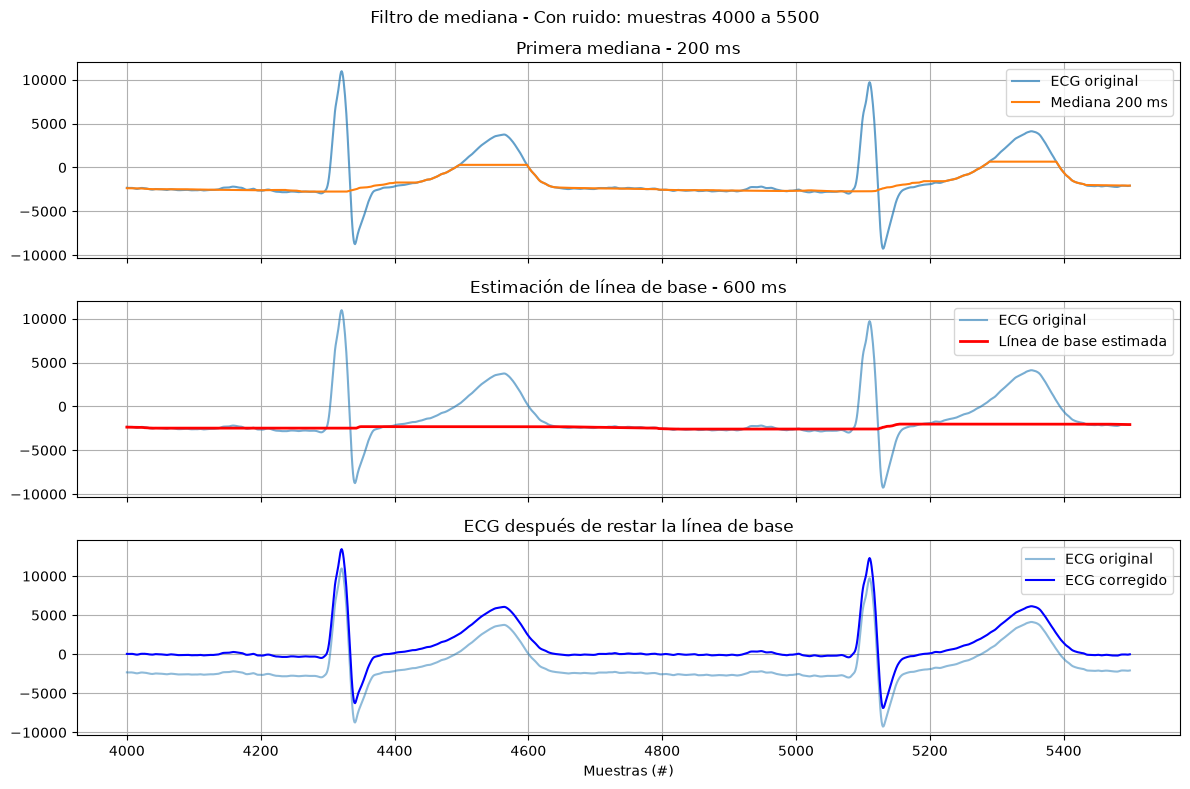

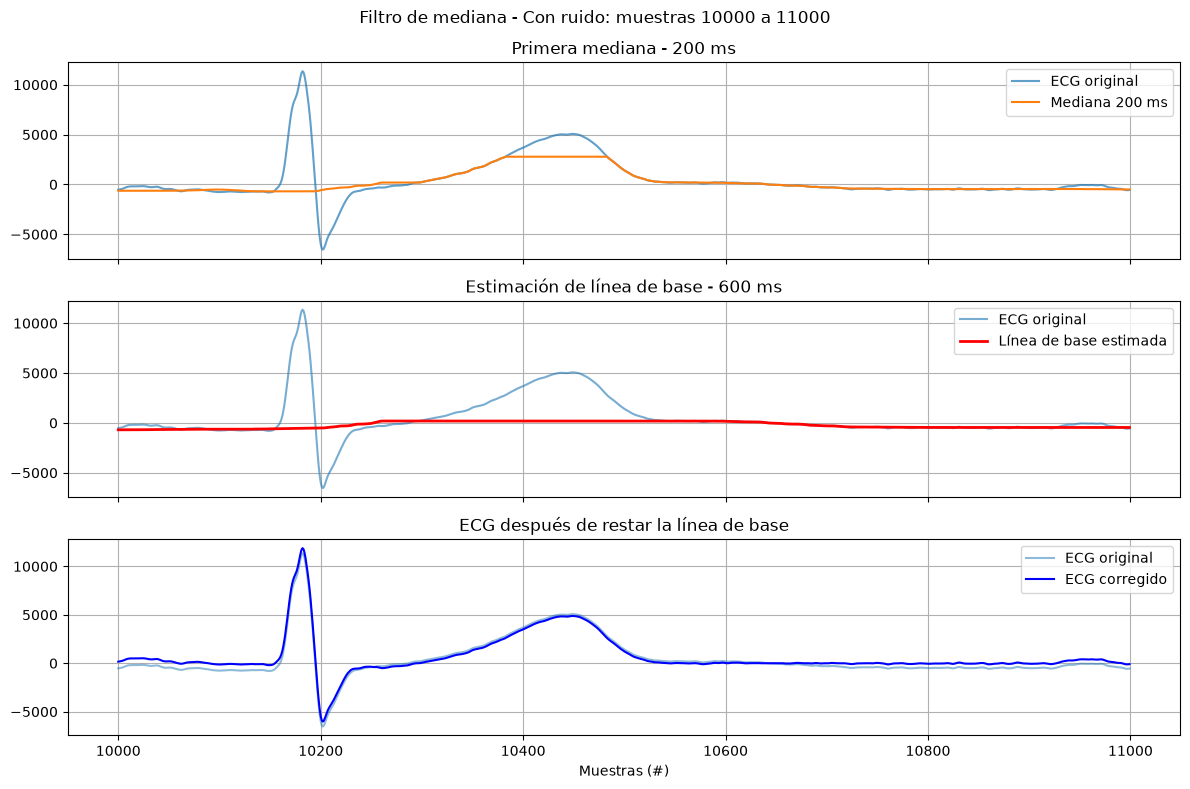

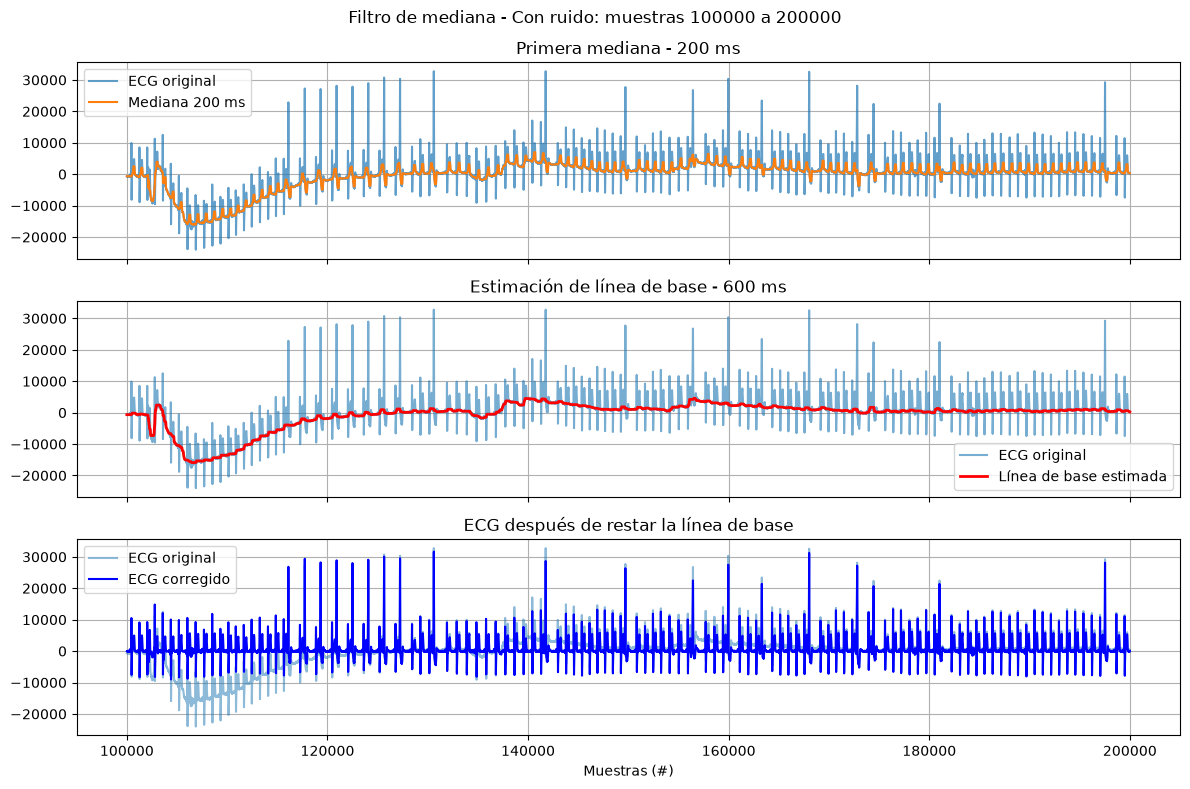

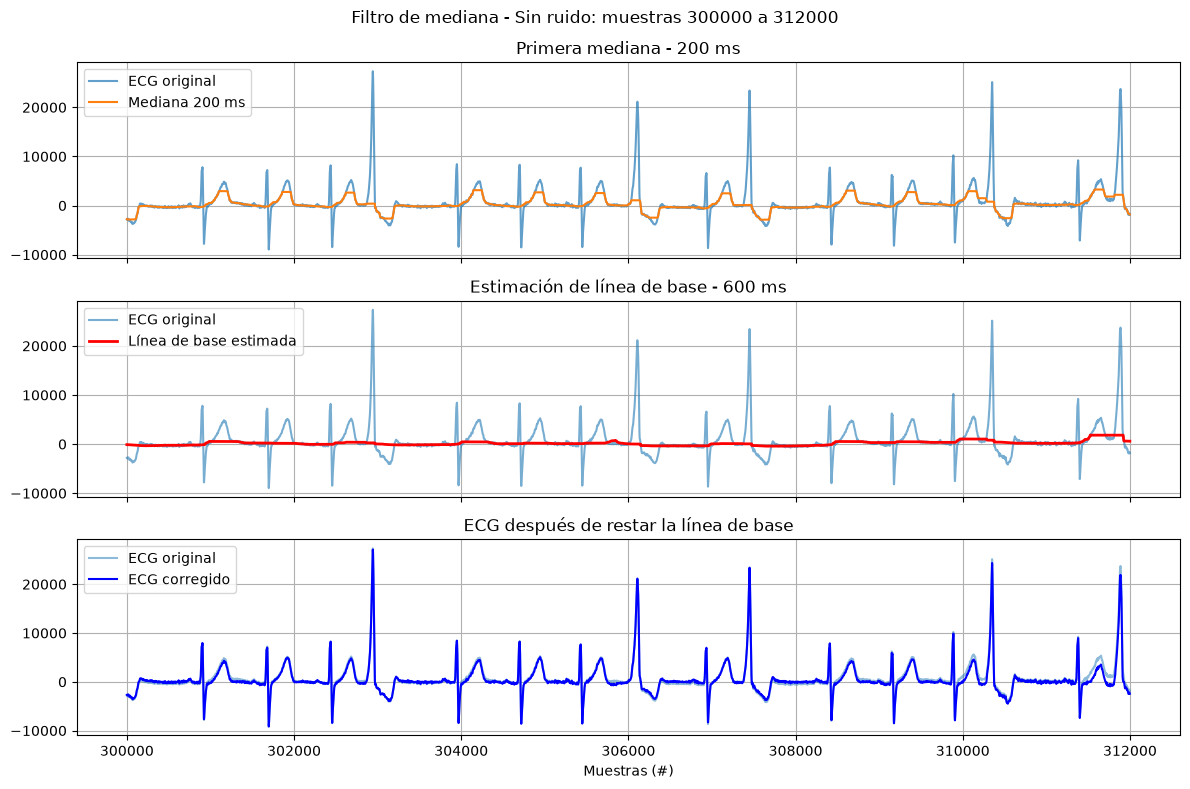

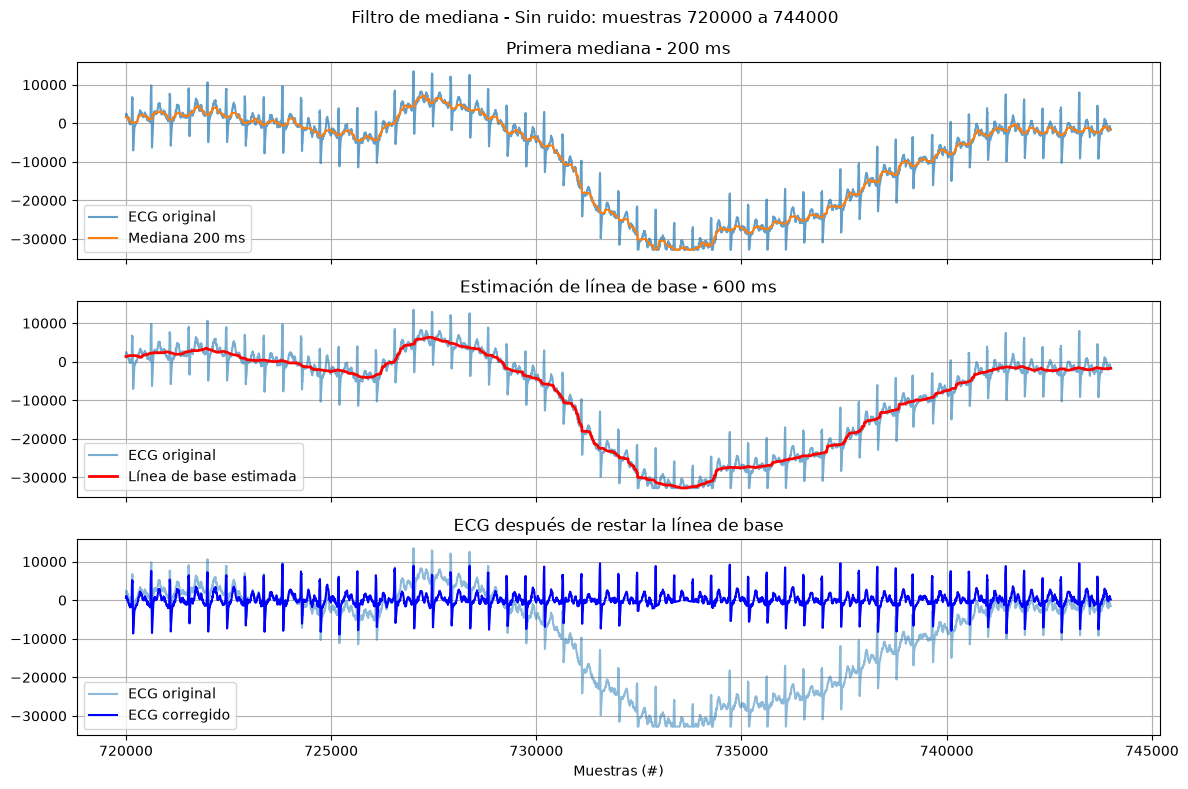

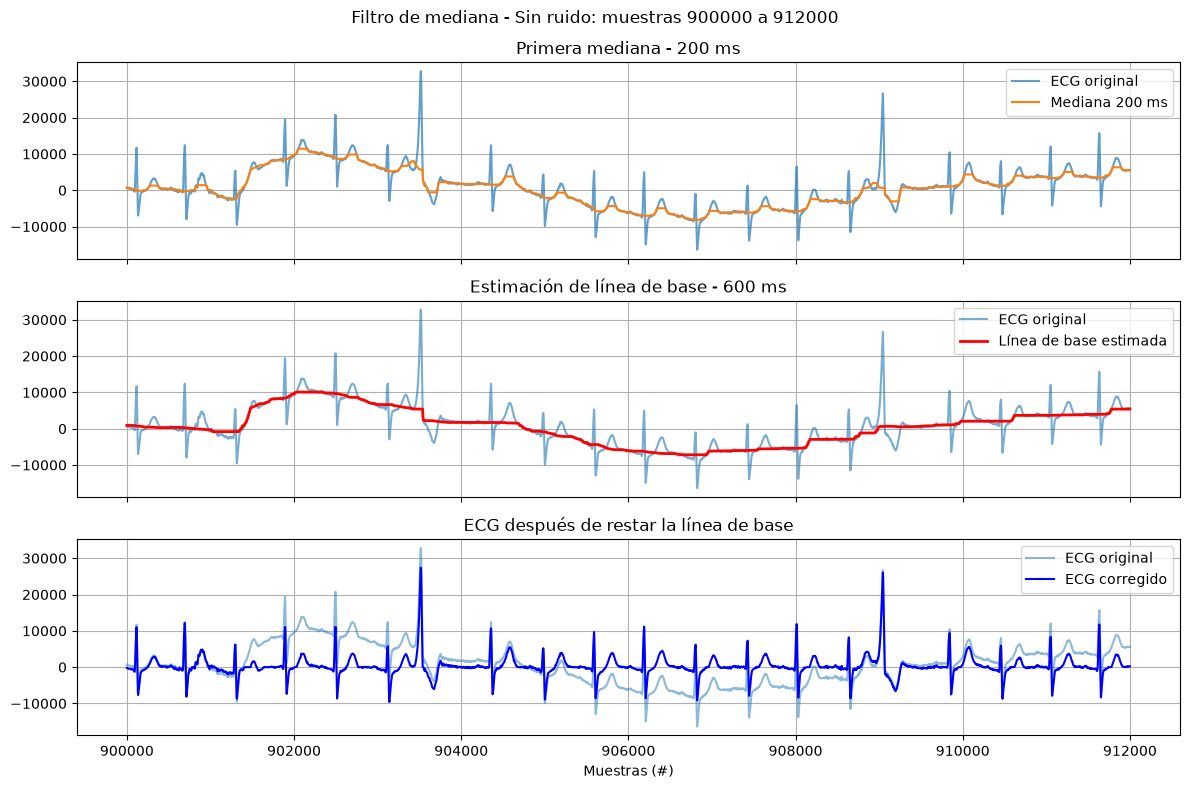

In [13]:
# -*- coding: utf-8 -*-
"""
TS8 - FILTRADO NO LINEAL
Analisis y Procesamiento de Señales
"""

import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
import scipy.io as sio
from scipy.interpolate import CubicSpline

plt.close('all')

#%% CARGA DE DATOS
# =============================================================================

# Cargar el archivo ECG
mat = sio.loadmat('ECG_TP4.mat')

s = mat['ecg_lead'].flatten()
fs = 1000  # Frecuencia de muestreo [Hz]
cant_muestras = len(s)
t = np.arange(cant_muestras) / fs

# Extraer detecciones reales provistas por la cátedra
qrs = mat['qrs_detections'].flatten().astype(int)


#%% 1) FILTRO DE MEDIANA


# Duración de las ventanas
t1 = 0.200  # 200 ms
t2 = 0.600  # 600 ms

# Conversión a cantidad de muestras y asegurar longitud impar
N1 = int(t1 * fs)
N1 = N1 + 1 if N1 % 2 == 0 else N1

N2 = int(t2 * fs)
N2 = N2 + 1 if N2 % 2 == 0 else N2

# Primera mediana: 200 ms (elimina picos QRS)
m_global = signal.medfilt(s, kernel_size=N1)

# Segunda mediana: 600 ms (extrae la componente lenta)
b_est_mediana = signal.medfilt(m_global, kernel_size=N2)

# ECG corregido global
ecg_mediana = s - b_est_mediana


#%% GRÁFICOS: FILTRO DE MEDIANA POR REGIONES
# =============================================================================

# Margen para evitar efectos de borde al filtrar por tramos
margen = N1//2 + N2//2


# Regiones con ruido (en muestras)
regs_ruido = (
    [4000, 5500],
    [10000, 11000],
    [100 * fs, 200 * fs],
)

# Regiones sin ruido (minutos a muestras)
regs_sin_ruido = (
    np.array([5, 5.2]) * 60 * fs,
    np.array([12, 12.4]) * 60 * fs,
    np.array([15, 15.2]) * 60 * fs,
)

regiones = {
    'Con ruido': regs_ruido,
    'Sin ruido': regs_sin_ruido
}

#%% Filtrado y gráficos

for tipo, regs_interes in regiones.items():

    for ii in regs_interes:

        inicio = int(max(0, ii[0]))
        fin = int(min(cant_muestras, ii[1]))

        if fin <= inicio:
            continue

        # Ampliamos la región para aplicar las medianas
        inicio_ext = max(0, inicio - margen)
        fin_ext = min(cant_muestras, fin + margen)

        s_region = s[inicio_ext:fin_ext]

        # Primera mediana: 200 ms
        med_200 = signal.medfilt(s_region, kernel_size=N1)

        # Segunda mediana: 600 ms
        b_est = signal.medfilt(med_200, kernel_size=N2)

        # Recortamos a la región de interés
        i0 = inicio - inicio_ext
        i1 = fin - inicio_ext

        ecg_original = s_region[i0:i1]
        mediana_200 = med_200[i0:i1]
        linea_base = b_est[i0:i1]

        # ECG corregido
        ecg_filtrado = ecg_original - linea_base

        zoom_region = np.arange(inicio, fin)

        # Gráficos
        fig, ax = plt.subplots(3, 1, figsize=(12, 8),
                               sharex=True)

        # Primera mediana
        ax[0].plot(zoom_region, ecg_original,
                   label='ECG original', alpha=0.7)

        ax[0].plot(zoom_region, mediana_200,
                   label='Mediana 200 ms')

        ax[0].set_title('Primera mediana - 200 ms')
        ax[0].legend()
        ax[0].grid()

        # Estimación de línea de base
        ax[1].plot(zoom_region, ecg_original,
                   label='ECG original', alpha=0.6)

        ax[1].plot(zoom_region, linea_base,
                   label='Línea de base estimada',
                   color='red', linewidth=2)

        ax[1].set_title('Estimación de línea de base - 600 ms')
        ax[1].legend()
        ax[1].grid()

        # ECG corregido
        ax[2].plot(zoom_region, ecg_original,
                   label='ECG original', alpha=0.5)

        ax[2].plot(zoom_region, ecg_filtrado,
                   label='ECG corregido', color='blue')

        ax[2].set_title('ECG después de restar la línea de base')
        ax[2].set_xlabel('Muestras (#)')
        ax[2].legend()
        ax[2].grid()

        plt.suptitle(
            f'Filtro de mediana - {tipo}: '
            f'muestras {inicio} a {fin}'
        )

        plt.tight_layout()
        plt.show()

Al observar los gráficos generados, podemos comprobar el buen comportamiento del filtro de mediana para estimar y corregir el movimiento de la línea de base en distintas condiciones del registro.

**Acción de la ventana de 200 ms:** En las regiones cortas (como las de 4000–5500 y 10000–11000 muestras), se ve claramente cómo la primera mediana recorta por completo los complejos QRS (los interpreta como ruido impulsivo debido a su corta duración), dejando una señal "plana" en esas zonas pero que aún conserva la forma de las ondas T, las cuales son más anchas y logran pasar esta primera ventana.

**Acción de la ventana de 600 ms:** La segunda pasada, con una ventana más grande, se encarga de atenuar los restos de las ondas T. Como resultado, la estimación final de la línea de base (en rojo) es una curva que sigue las variaciones lentas de la señal, sin verse significativamente afectada por los eventos eléctricos rápidos del corazón.

**Comportamiento en regiones sin ruido:** En las regiones donde la línea de base es relativamente estable, la corrección introduce pocas modificaciones en la señal original. Sin embargo, también observamos que algunas de las regiones seleccionadas como libres de ruido presentan desplazamientos importantes de la línea de base, como ocurre entre las muestras 720000 y 744000. En estos casos, el filtro logra estimar y compensar dichas variaciones.

**Corrección en zonas extremas:** El gráfico correspondiente al intervalo de 100000 a 200000 muestras muestra un tramo del ECG con una fluctuación muy pronunciada de la línea de base, que alcanza amplitudes negativas cercanas a −20000. La estimación mediante medianas logra seguir esta deriva y, al realizar la resta, el ECG corregido (en azul) queda mucho más estabilizado alrededor de cero, conservando los complejos QRS y reduciendo considerablemente la interferencia original.


### 2) Interpolación mediante splines cúbicos 

El segundo método que implementamos para corregir la deriva del ECG es la interpolación por splines cúbicos. La idea de esta técnica es aislar la tendencia de fondo reconstruyendo una curva continua a partir de ciertos "puntos ancla" o nodos. A diferencia de la interpolación lineal, que une los puntos con líneas rectas generando quiebres angulosos que meten ruido de alta frecuencia, o de la interpolación de Lagrange, que usa un solo polinomio gigante y provoca oscilaciones violentas en los extremos (fenómeno de Runge), el spline divide el problema armando un polinomio de tercer grado distinto para cada tramo entre dos nodos vecinos.

La gran ventaja de usar un spline cúbico es la suavidad matemática extrema que logra. El algoritmo impone que en cada punto de unión se cumplan tres condiciones de empalme perfecto: continuidad de la función (sin saltos), continuidad de la primera derivada (misma pendiente, sin vértices) y continuidad de la segunda derivada (mismo radio de curvatura). Esto genera una envolvente fluida y físicamente natural con un costo computacional bajísimo. 

Sin embargo, lo malo de este método es que es completamente dependiente a la señal y depende de un algoritmo previo: si los puntos de anclaje están mal elegidos, la curva se arruina. Para aplicarlo con éxito a nuestro ECG, necesitamos que los nodos caigan exactamente en zonas de reposo eléctrico (el nivel isoeléctrico). Por eso, utilizamos las detecciones de los complejos QRS provistas por la cátedra y retrocedimos 80 milisegundos (un desplazamiento temporal $n_0$) para asegurarnos de clavar los nodos justo en la estabilidad del segmento PQ. Una vez calculada la curva que une estos puntos en reposo, obtenemos una excelente estimación de la línea de base respiratoria para restársela al registro original y aplanarlo.

A continuación, vamos a ubicar estos puntos ancla en la señal real y graficarlos para comprobar visualmente que las marcas (nodos verdes) caigan efectivamente en el nivel isoeléctrico previo a cada contracción.

Cantidad de QRS detectados: 1903


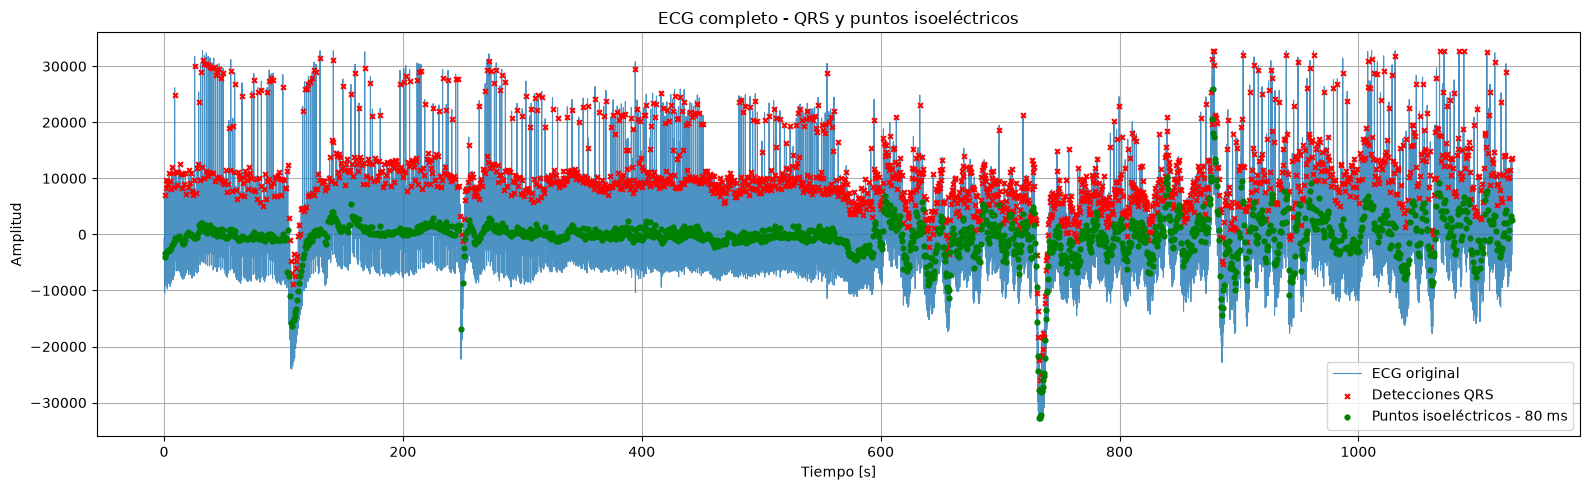

In [14]:
from scipy.interpolate import CubicSpline

# ============================================================
# 1. DETECCIONES QRS Y PUNTOS ISOELECTRICOS
# ============================================================

# Detecciones QRS provistas en el archivo
qrs = mat['qrs_detections'].flatten().astype(int)
qrs = np.unique(qrs[(qrs >= 0) & (qrs < len(s))])

print("Cantidad de QRS detectados:", len(qrs))

# Desplazamiento respecto de cada QRS (80 ms)
n0 = int(0.08 * fs)

# Puntos de referencia para estimar la linea de base
m = qrs - n0
m = np.unique(m[(m >= 0) & (m < len(s))])

# Vector temporal
t = np.arange(len(s)) / fs

# ============================================================
# 2. ECG COMPLETO CON QRS Y PUNTOS ISOELECTRICOS
# ============================================================

plt.figure(figsize=(16, 5))
plt.plot(t, s, label='ECG original', linewidth=0.8, alpha=0.8)
plt.scatter(qrs / fs, s[qrs], color='red', marker='x', s=12, label='Detecciones QRS', zorder=3)
plt.scatter(m / fs, s[m], color='green', marker='o', s=12, label='Puntos isoeléctricos - 80 ms', zorder=4)

plt.title('ECG completo - QRS y puntos isoeléctricos')
plt.xlabel('Tiempo [s]')
plt.ylabel('Amplitud')
plt.grid()
plt.legend()
plt.tight_layout()
plt.show()

Al visualizar el registro completo, podemos dimensionar la gran cantidad de datos procesados (1903 latidos detectados). La nube de puntos rojos (picos QRS) y verdes (nodos isoeléctricos) nos permite comprobar que el algoritmo logró anclar puntos a lo largo de toda la señal, siguiendo a grandes rasgos la brutal variación y deriva de la línea de base durante los más de 15 minutos que dura el registro. 

Sin embargo, a esta escala macroscópica no podemos evaluar la precisión fina del método.

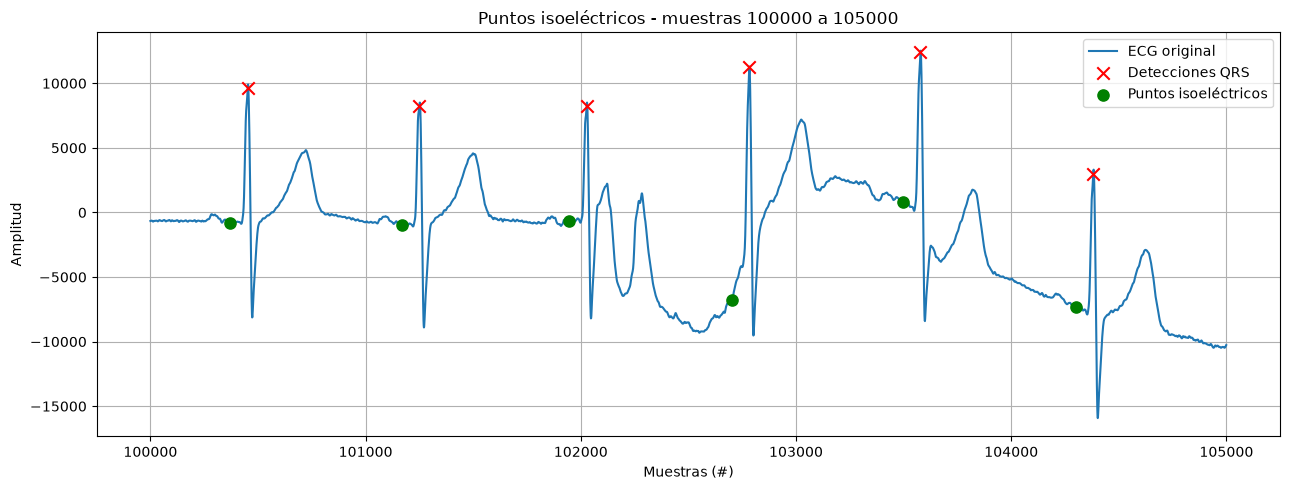

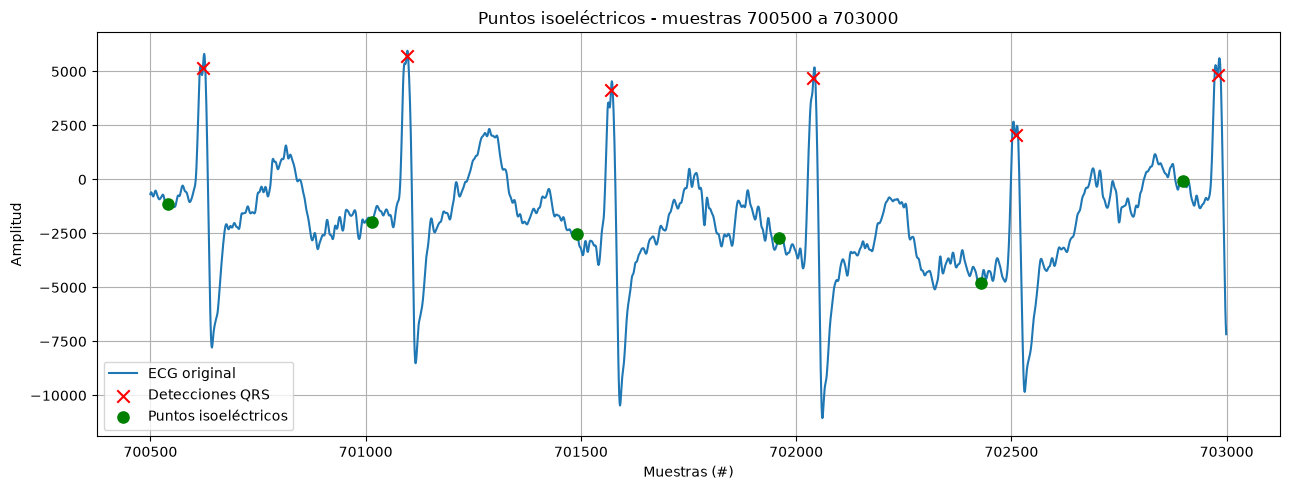

In [15]:
# ============================================================
# 3. ZOOM PARA VERIFICAR LOS PUNTOS ISOELECTRICOS
# ============================================================

# Regiones para inspeccionar la ubicacion de los puntos
regs_zoom = (
    [100 * fs, 105 * fs],
    [700500, 703000],  # Zona añadida para evaluar ectópicos
)

for ii in regs_zoom:
    inicio = int(max(0, ii[0]))
    fin = int(min(len(s), ii[1]))

    if fin <= inicio: continue

    zoom_region = np.arange(inicio, fin)
    qrs_region = qrs[(qrs >= inicio) & (qrs < fin)]
    m_region = m[(m >= inicio) & (m < fin)]

    plt.figure(figsize=(13, 5))
    plt.plot(zoom_region, s[zoom_region], label='ECG original', linewidth=1.5)
    plt.scatter(qrs_region, s[qrs_region], color='red', marker='x', s=80, label='Detecciones QRS', zorder=4)
    plt.scatter(m_region, s[m_region], color='green', marker='o', s=65, label='Puntos isoeléctricos', zorder=5)

    plt.title(f'Puntos isoeléctricos - muestras {inicio} a {fin}')
    plt.xlabel('Muestras (#)')
    plt.ylabel('Amplitud')
    plt.grid()
    plt.legend()
    plt.tight_layout()
    plt.show()

Los gráficos de selección de nodos exponen claramente el principal problema de la interpolación por splines. Al utilizar un desplazamiento temporal fijo y estático (retroceder exactamente 80 ms desde el pico R), asumimos que el ritmo cardíaco y la morfología del ECG son perfectamente constantes a lo largo del tiempo. Sin embargo, al analizar tramos específicos del registro, evidenciamos que esto no siempre se cumple.

**Análisis de la región 100.000 a 105.000 (Deriva Severa)**
En este primer panel, observamos latidos sinusales normales pero afectados por un intenso movimiento de la línea de base. Si observamos los tres primeros latidos (muestras 100.000 a 102.000), el algoritmo funciona excelente: los nodos verdes caen exactamente en el reposo del segmento PQ. Pero si miramos los últimos tres latidos, la señal sufre oscilaciones violentas. Al aplicar el retraso ciego de 80 ms, los nodos terminan cayendo en medio de pendientes pronunciadas, en lugar de anclarse en un verdadero nivel isoeléctrico.

**Análisis de la región 700.500 a 703.000 (Latido Ectópico)**
El segundo panel ilustra un problema aún mayor: el cambio en la morfología intrínseca del latido. Alrededor de la muestra 702.500, el paciente presenta un latido de morfología aberrante (posiblemente una extrasístole ventricular), el cual es mucho más ancho que los latidos normales. Al restarle estáticamente 80 ms a este latido, el punto verde cae prematuramente sobre la onda de despolarización ensanchada, a una amplitud fuertemente negativa, fallando por completo en capturar el nivel de reposo.

Como el spline obliga matemáticamente a que la estimación pase por todos estos puntos, anclar un nodo en una pendiente errónea o sobre la onda de un latido ensanchado provocará que la línea de base estimada se deforme en ese tramo. Para garantizar una estimación verdaderamente robusta, el algoritmo no debería usar un retardo temporal fijo, sino buscar de manera dinámica el tramo de menor derivada (mayor planitud) en una ventana previa a cada complejo QRS detectado.

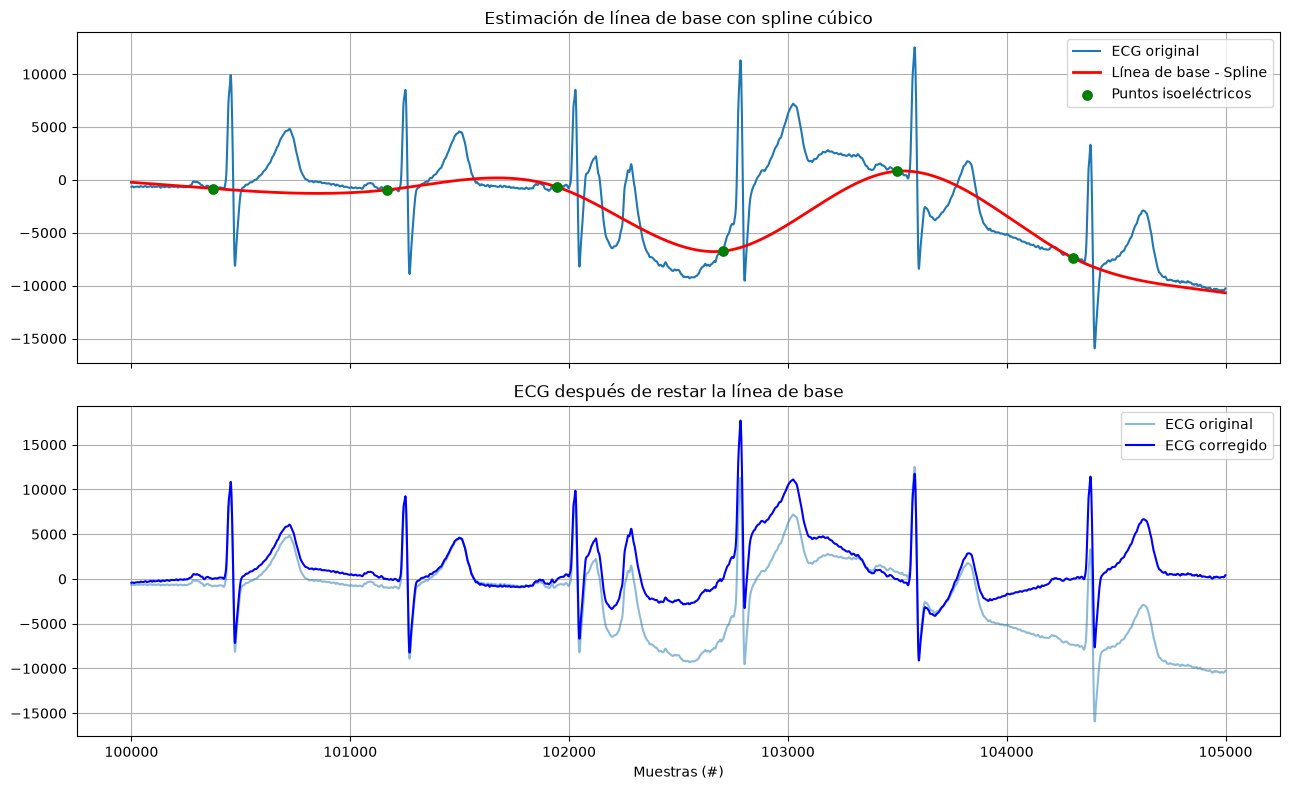

In [16]:
# ============================================================
# 4. INTERPOLACION MEDIANTE SPLINES CUBICOS
# ============================================================

valores = s[m]
spline = CubicSpline(m, valores, bc_type='natural')
n = np.arange(len(s))
b_spline = spline(np.clip(n, m[0], m[-1]))
ecg_spline = s - b_spline

# ============================================================
# 5. GRAFICOS - SPLINE CUBICO (100 A 105 SEGUNDOS)
# ============================================================

inicio = int(100 * fs)
fin = int(105 * fs)
zoom_region = np.arange(inicio, fin)
m_region = m[(m >= inicio) & (m < fin)]

fig, ax = plt.subplots(2, 1, figsize=(13, 8), sharex=True)

ax[0].plot(zoom_region, s[zoom_region], label='ECG original')
ax[0].plot(zoom_region, b_spline[zoom_region], label='Línea de base - Spline', color='red', linewidth=2)
ax[0].scatter(m_region, s[m_region], color='green', s=45, label='Puntos isoeléctricos', zorder=5)
ax[0].set_title('Estimación de línea de base con spline cúbico')
ax[0].legend()
ax[0].grid()

ax[1].plot(zoom_region, s[zoom_region], label='ECG original', alpha=0.5)
ax[1].plot(zoom_region, ecg_spline[zoom_region], label='ECG corregido', color='blue')
ax[1].set_title('ECG después de restar la línea de base')
ax[1].set_xlabel('Muestras (#)')
ax[1].legend()
ax[1].grid()

plt.tight_layout()
plt.show()

Al graficar la estimación del spline superpuesta sobre la región con deriva severa (muestras 100.000 a 105.000), podemos observar lo que mencionamos anteriormente.

En el panel superior, la curva de interpolación (en rojo) cumple a la perfección con su mandato matemático: traza un polinomio de máxima suavidad que une todos los puntos de anclaje (nodos verdes). Sin embargo, como demostramos que los últimos nodos cayeron sobre pendientes pronunciadas debido al uso del retardo estático de 80 ms, el spline se ve obligado a oscilar de manera exagerada y artificial para poder alcanzarlos. La curva roja resultante deja de ser una estimación fiel del nivel isoeléctrico y se convierte en una distorsión.

En el panel inferior observamos el resultado final. Si bien la resta de esta estimación logra levantar la señal y centrarla alrededor del cero, el proceso transfiere el error del polinomio a la señal corregida (azul oscuro). A diferencia del filtro de mediana que lograba un aplanamiento casi perfecto, en esta región la corrección por splines presenta "lomas" y valles artificiales entre los latidos. Esto confirma que la calidad de la interpolación cúbica es directamente proporcional a la calidad de su algoritmo de detección de nodos: un nodo mal anclado se traduce inevitablemente en una deformación de la línea de base corregida.

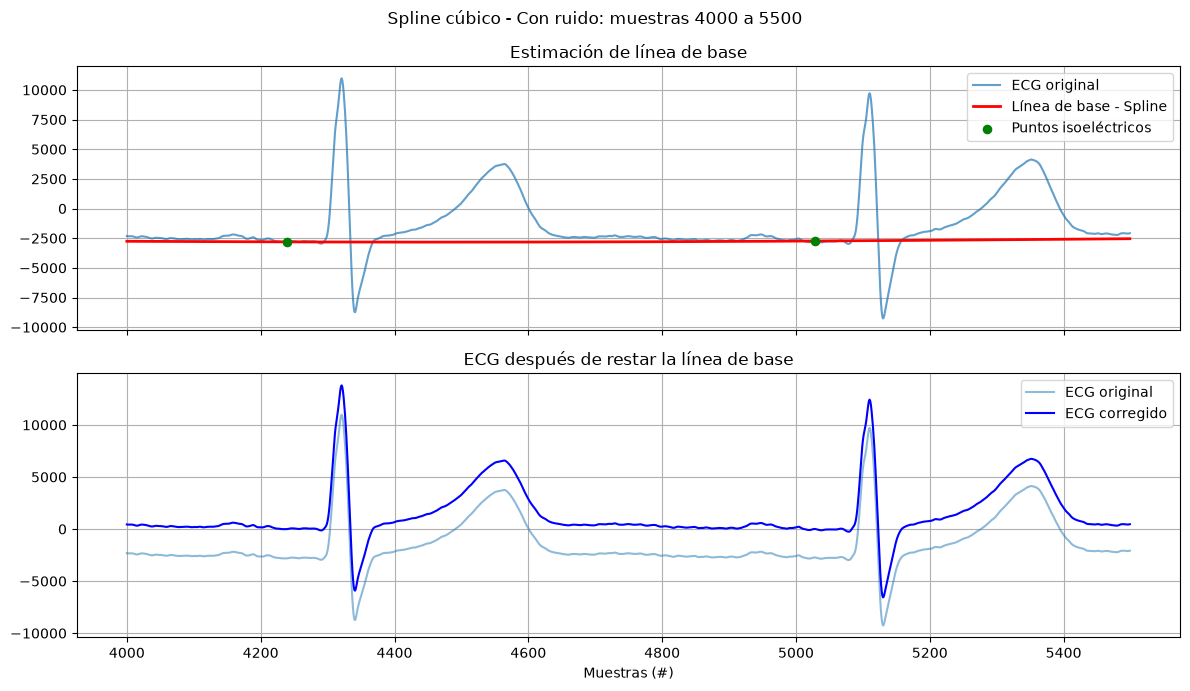

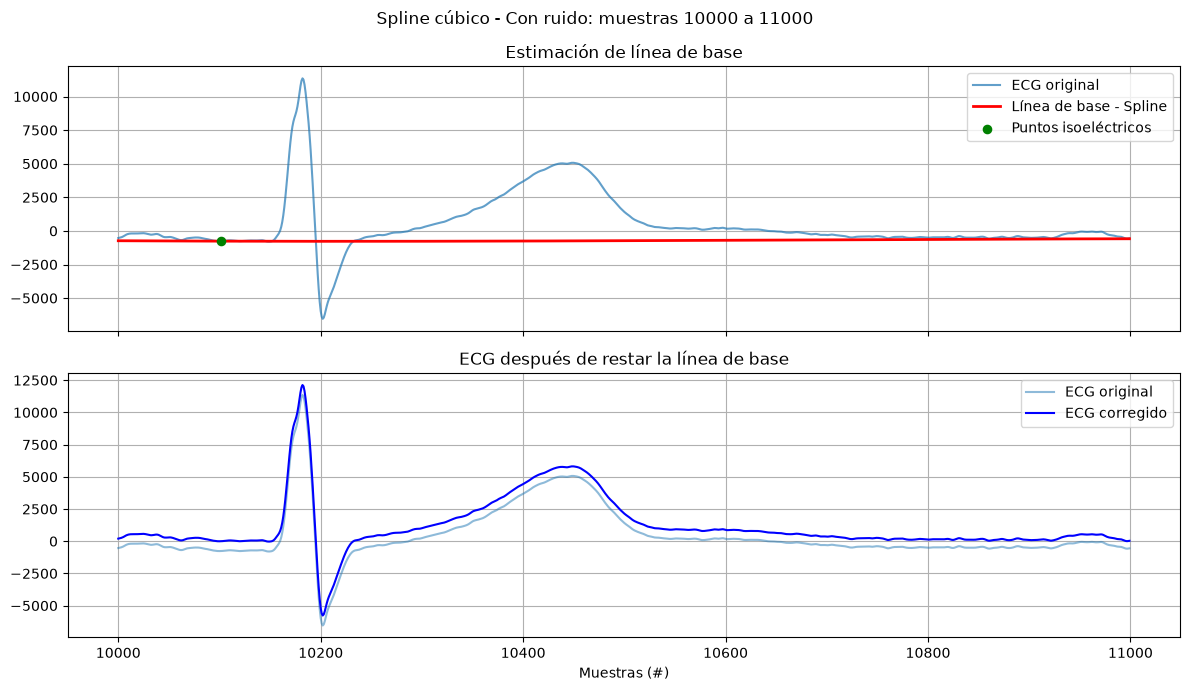

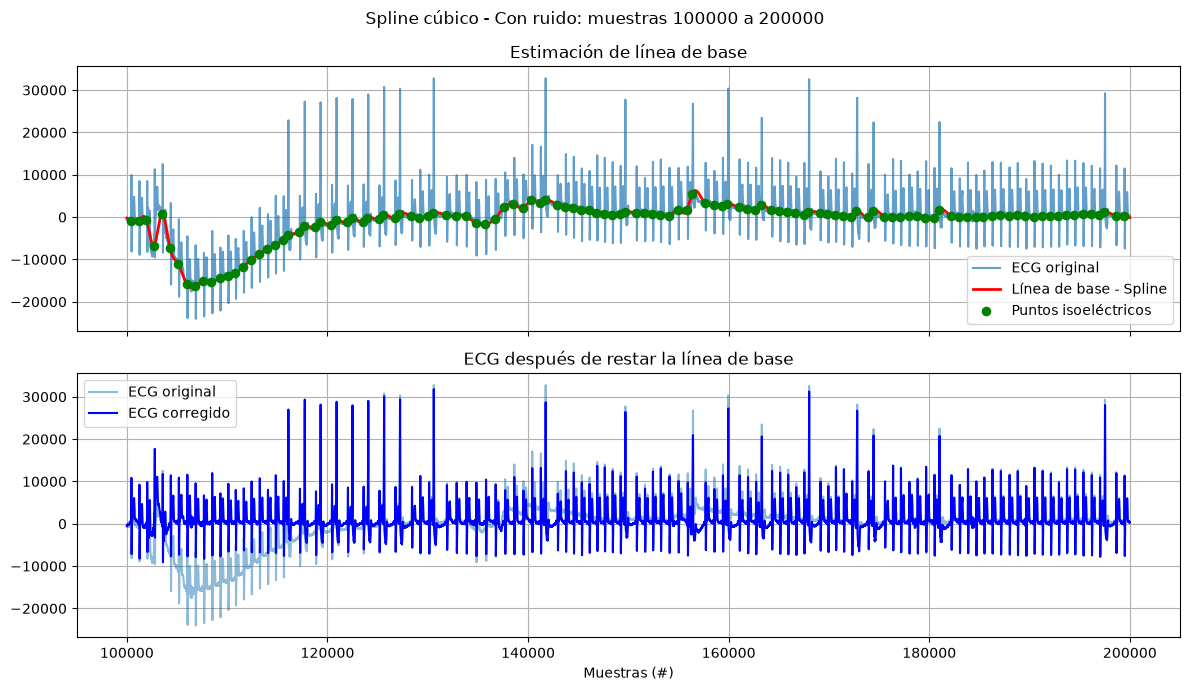

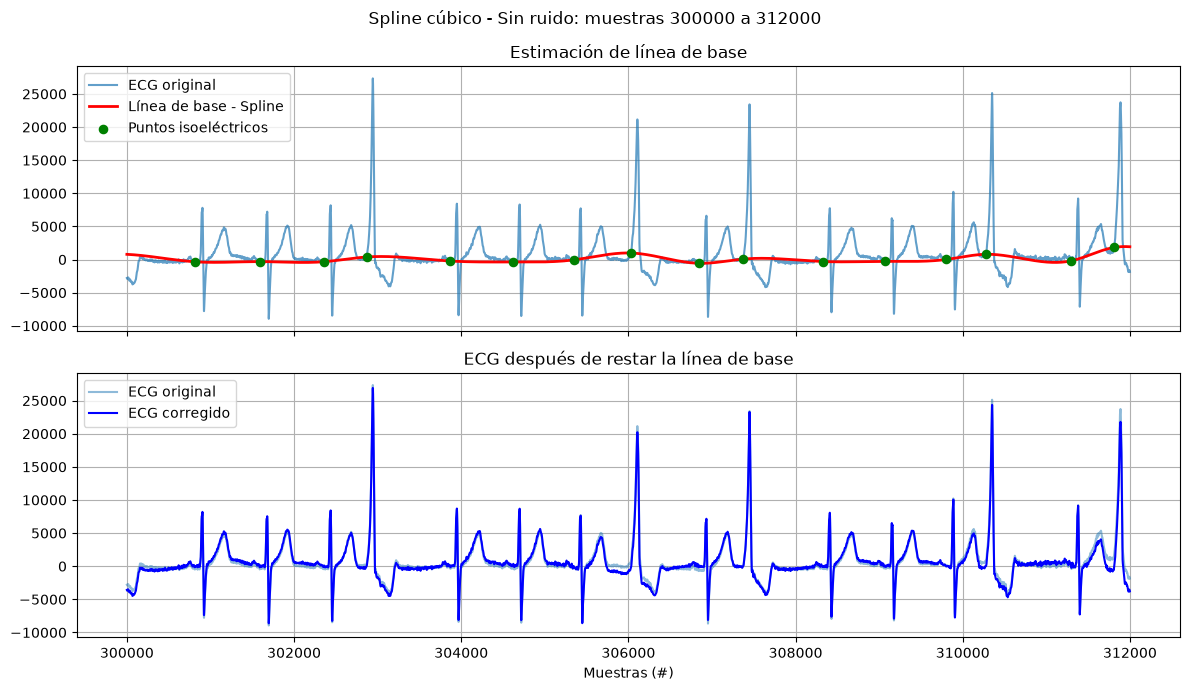

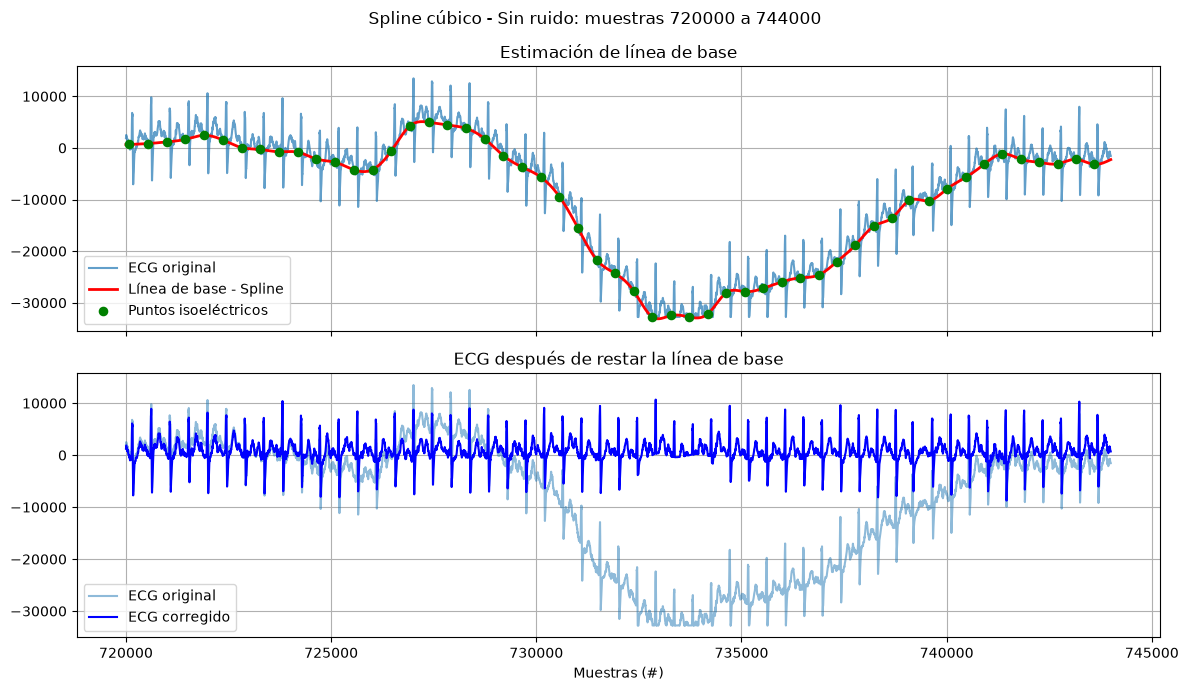

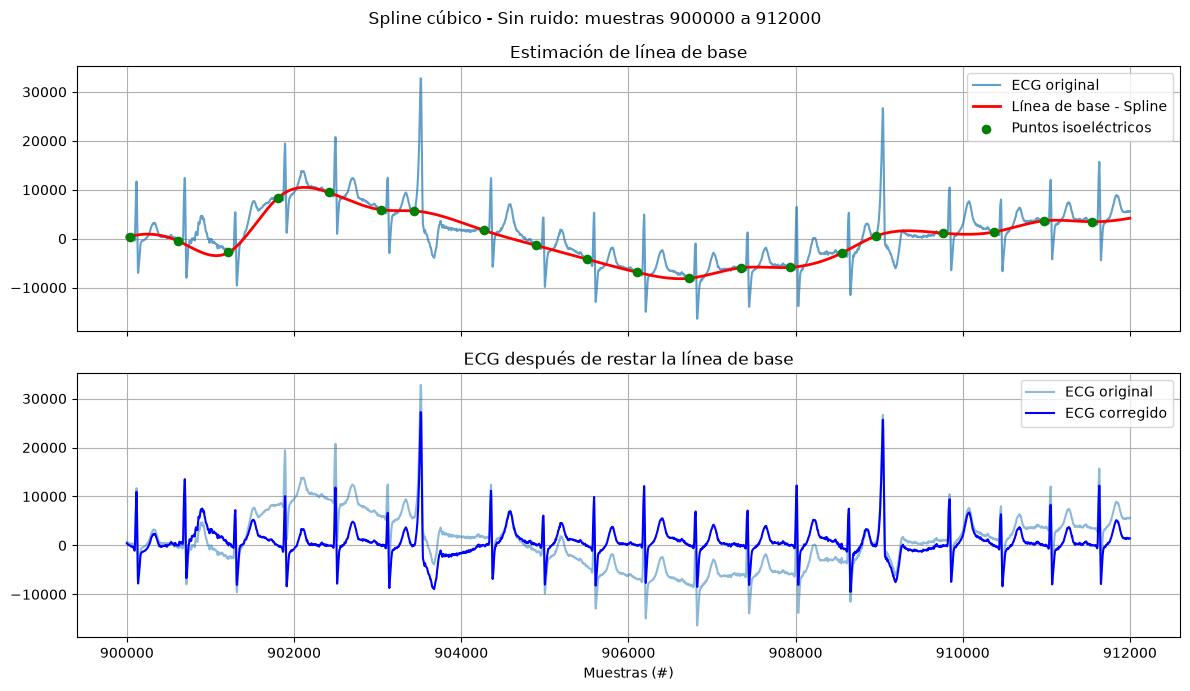

In [17]:
# ============================================================
# 6. REGIONES DE INTERES - SPLINES CUBICOS
# ============================================================

cant_muestras = len(s)

regs_ruido = (
    [4000, 5500],
    [10000, 11000],
    [100 * fs, 200 * fs],
)

regs_sin_ruido = (
    np.array([5, 5.2]) * 60 * fs,
    np.array([12, 12.4]) * 60 * fs,
    np.array([15, 15.2]) * 60 * fs,
)

regiones = {
    'Con ruido': regs_ruido,
    'Sin ruido': regs_sin_ruido
}

for tipo, regs_interes in regiones.items():
    for ii in regs_interes:
        inicio = int(max(0, ii[0]))
        fin = int(min(cant_muestras, ii[1]))

        if fin <= inicio: continue
        zoom_region = np.arange(inicio, fin)
        m_region = m[(m >= inicio) & (m < fin)]

        fig, ax = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

        ax[0].plot(zoom_region, s[zoom_region], label='ECG original', alpha=0.7)
        ax[0].plot(zoom_region, b_spline[zoom_region], label='Línea de base - Spline', color='red', linewidth=2)
        ax[0].scatter(m_region, s[m_region], color='green', s=35, label='Puntos isoeléctricos', zorder=5)
        ax[0].set_title('Estimación de línea de base')
        ax[0].legend()
        ax[0].grid()

        ax[1].plot(zoom_region, s[zoom_region], label='ECG original', alpha=0.5)
        ax[1].plot(zoom_region, ecg_spline[zoom_region], label='ECG corregido', color='blue')
        ax[1].set_title('ECG después de restar la línea de base')
        ax[1].set_xlabel('Muestras (#)')
        ax[1].legend()
        ax[1].grid()

        plt.suptitle(f'Spline cúbico - {tipo}: muestras {inicio} a {fin}')
        plt.tight_layout()
        plt.show()

En contraste con las deformaciones observadas en la región de deriva severa, este gráfico (correspondiente a las muestras 4000 a 5500) nos muestra un escenario donde el método de splines funciona muy bien. 

Aunque esta zona presenta ruido, localmente no sufre oscilaciones violentas de baja frecuencia. Gracias a esto, la regla estática de retroceder 80 ms funciona a la perfección: los puntos verdes (nodos) caen exactamente en la zona plana del segmento PQ, capturando el verdadero nivel isoeléctrico en reposo.

Al estar los puntos de anclaje bien ubicados y alineados a niveles de amplitud coherentes, el algoritmo del spline cúbico (curva roja) no necesita realizar ningún esfuerzo matemático desproporcionado para unirlos. Como se observa, el polinomio traza una línea suave y casi perfectamente horizontal que calca la verdadera tendencia de fondo sin introducir artefactos. 

Esto confirma nuestra conclusión: la matemática de la interpolación por splines es impecable, no afecta la morfología de los latidos y es computacionalmente eficiente. Su única limitación en un entorno clínico real no radica en el trazado de la curva, sino en la necesidad de un detector de nodos más inteligente que un simple retardo temporal estático.

### 3) Filtro Adaptado (Matched Filter)

#### Parte a) Fundamento conceptual y discusión del método

A diferencia de los métodos anteriores, cuyo propósito era **estimar y sustraer la línea de base**, el filtro adaptado busca **detectar los complejos QRS**. Para ello, aprovechamos el patrón suministrado por la cátedra en la variable `qrs_pattern1`.

Un filtro adaptado es un **filtro lineal FIR** cuya respuesta al impulso se obtiene invirtiendo temporalmente un patrón conocido:

$$h[n]=p[L-1-n],$$

donde $p[n]$ es el patrón de longitud $L$. Convolucionar el ECG con $h[n]$ equivale a **correlacionarlo con el patrón**, de manera que aparecen máximos de coincidencia cuando se encuentra una forma semejante a la plantilla. Por lo tanto, este método **depende 100% de la señal**: requiere indefectiblemente conocer (o estimar) una plantilla de referencia previa, y su desempeño de detección quedará atado a la similitud morfológica entre dicho molde y los latidos reales presentes en el registro.

**Diseño del detector:**
Siguiendo lo visto en clase, primero aplicamos un filtro Butterworth pasabajos de segundo orden, con frecuencia de corte de 15 Hz, para atenuar las componentes de alta frecuencia del ECG. Posteriormente, normalizamos tanto la señal preprocesada como el patrón QRS, restándoles la media y dividiéndolos por su desvío estándar. Luego calculamos la correlación mediante `scipy.signal.correlate`y tomamos su valor absoluto para considerar también coincidencias con signo opuesto.

Finalmente, se utilizó `signal.find_peaks` para localizar los máximos de la señal de detección. Se estableció una separación mínima de 300 muestras (300 ms), con el objetivo de evitar múltiples detecciones asociadas a un mismo latido. Además, se fijó una prominencia mínima igual al desvío estándar de la señal de detección, para descartar máximos poco destacados respecto de su entorno.

Cabe destacar que el filtro adaptado en sí es lineal, mientras que las operaciones de valor absoluto y selección de máximos forman parte de la etapa no lineal de detección. Por otra parte, la posición de los máximos de correlación no necesariamente coincide con la posición de los QRS de referencia, debido a la alineación temporal de la plantilla y la implementación de la correlación. Para contemplar este desplazamiento, utilizamos la posición del pico dominante del patrón y los retardos obtenidos mediante `correlation_lags`, cuya alineación verificaremos posteriormente en los gráficos.

**Utilidad y ventajas:**
La principal ventaja de este método es que transforma un problema complejo de reconocimiento de formas en una simple umbralización de energía. Combinado con las herramientas de `find_peaks`, permite sintonizar de manera fina el compromiso entre la sensibilidad del detector y el rechazo de falsas detecciones.

**Limitaciones:**
Su principal limitación es la dependencia estricta de la plantilla. Un QRS de origen ectópico, ensanchado o invertido producirá una respuesta de menor amplitud o un máximo desplazado. Asimismo, el valor absoluto puede llegar a resaltar ondas T picudas. Finalmente, si bien el prefiltrado atenúa la deriva, el método no garantiza inmunidad frente a ruidos bruscos o de gran amplitud.

---

#### Parte b) Implementación y evaluación de desempeño

A continuación, se presenta el código implementado y la evaluación visual y cuantitativa de su desempeño en las distintas regiones del registro.

Longitud del patron: 113 muestras
Latidos de referencia: 1903


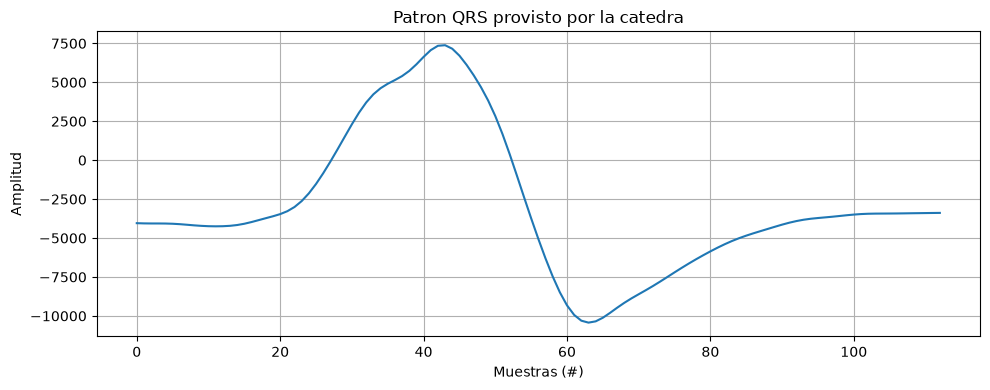

Separacion minima: 300 muestras
Prominencia elegida: 0.138
Indice del pico dominante del patron: 43
Latidos detectados: 1907


In [18]:
#%% 3) FILTRO ADAPTADO - MATCHED FILTER
# =============================================================================

# 1. PATRON QRS Y DETECCIONES DE REFERENCIA
patron = mat['qrs_pattern1'].flatten().astype(float)
qrs_ref = mat['qrs_detections'].flatten().astype(int)
qrs_ref = np.unique(qrs_ref[(qrs_ref >= 0) & (qrs_ref < len(s))])

print('Longitud del patron:', len(patron), 'muestras')
print('Latidos de referencia:', len(qrs_ref))

plt.figure(figsize=(10, 4))
plt.plot(np.arange(len(patron)), patron, color='C0')
plt.title('Patron QRS provisto por la catedra')
plt.xlabel('Muestras (#)')
plt.ylabel('Amplitud')
plt.grid(True)
plt.tight_layout()
plt.show()

# 2. PREPROCESAMIENTO
# Filtro pasabajos Butterworth de orden 2
# Frecuencia de corte: 15 Hz
sos = signal.butter(2, 15, btype='lowpass',
                    fs=fs, output='sos')

ecg_pre = signal.sosfiltfilt(sos, s.astype(float))
# Normalizacion: media cero y desviacion estandar unitaria.
std_ecg = np.std(ecg_pre)
std_patron = np.std(patron)
if std_ecg == 0 or std_patron == 0:
    raise ValueError('La señal ECG o el patron QRS tiene desviacion estandar nula.')

ecg_norm = (ecg_pre - np.mean(ecg_pre)) / std_ecg
patron_norm = (patron - np.mean(patron)) / std_patron

# 3. FILTRO ADAPTADO = CORRELACION CON LA PLANTILLA
salida_fa = signal.correlate(ecg_norm, patron_norm,
                            mode='same', method='fft')
salida_fa = salida_fa / len(patron_norm)  # Escala conveniente

# Para saber donde comienza la plantilla en la señal cuando hay coincidencia:
lags = signal.correlation_lags(len(ecg_norm), len(patron_norm),
                               mode='same')

# 4. SEÑAL DE DETECCION: valor absoluto de la correlacion
deteccion = np.abs(salida_fa)

# 5. DETECCION DE PICOS (valores iniciales para ajustar)
distancia_min = int(0.30 * fs)  # 300 ms entre detecciones
prominencia_min = 1.0 * np.std(deteccion)

peaks, propiedades = signal.find_peaks(
    deteccion,
    distance=distancia_min,
    prominence=prominencia_min
)

# 6. ALINEACION TEMPORAL
# El maximo de correlacion corresponde al inicio de la plantilla (lag)
# mas la posicion del pico dominante dentro de la plantilla.
pos_qrs_patron = int(np.argmax(np.abs(patron_norm)))
qrs_detectados = lags[peaks] + pos_qrs_patron
qrs_detectados = np.unique(qrs_detectados[
    (qrs_detectados >= 0) & (qrs_detectados < len(s))
])

print('Separacion minima:', distancia_min, 'muestras')
print('Prominencia elegida:', round(prominencia_min, 3))
print('Indice del pico dominante del patron:', pos_qrs_patron)
print('Latidos detectados:', len(qrs_detectados))

En los siguientes gráficos superponemos el ECG original (azul), la magnitud de la correlación (naranja), las detecciones de referencia (cruces rojas) y las obtenidas mediante `find_peaks` (círculos verdes). 

Para poder representar ambas señales en un mismo eje, cada una se escala por su máximo absoluto exclusivamente para la visualización, por lo que sus amplitudes no son directamente comparables. 

A continuación, se presenta primero el registro completo y, posteriormente, un acercamiento al intervalo de 326 a 338 segundos, que permitirá analizar con mayor detalle la coincidencia temporal entre las detecciones obtenidas y las de referencia.

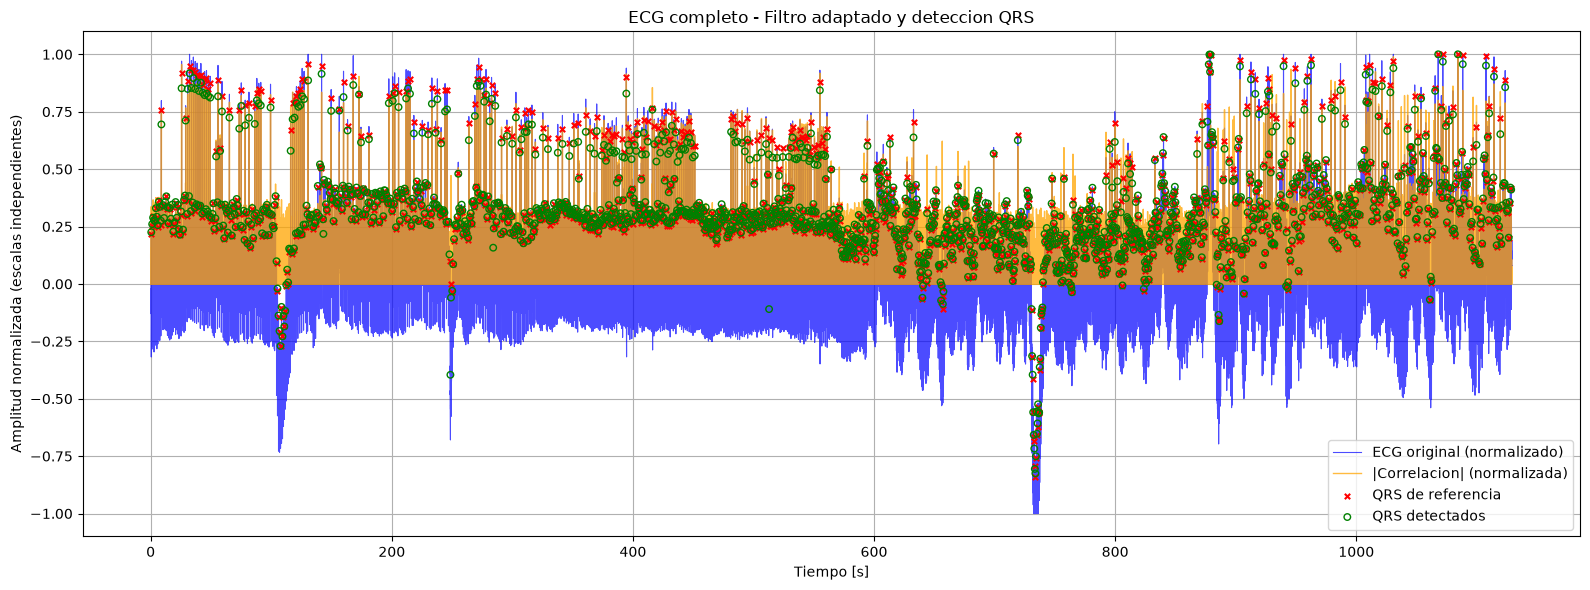

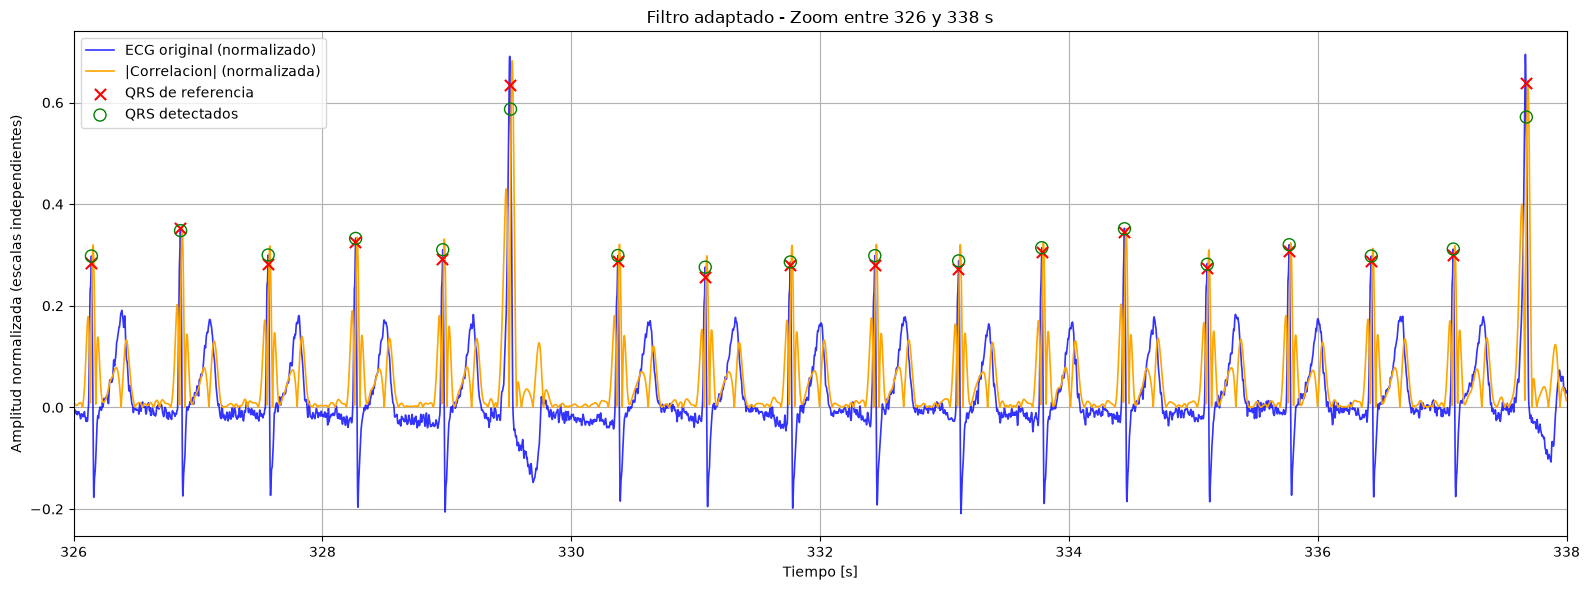

In [19]:
#%% GRAFICOS DEL FILTRO ADAPTADO - ECG COMPLETO Y ZOOM
# =============================================================================

# Normalizacion SOLO para representar las dos curvas en un mismo eje
escala_ecg = max(float(np.max(np.abs(s))), 1e-12)
escala_det = max(float(np.max(deteccion)), 1e-12)
ecg_graf = s / escala_ecg
deteccion_graf = deteccion / escala_det

t = np.arange(len(s)) / fs

# Grafico 1: ECG completo
plt.figure(figsize=(16, 6))
plt.plot(t, ecg_graf, color='blue', linewidth=0.8,
         alpha=0.7, label='ECG original (normalizado)')
plt.plot(t, deteccion_graf, color='orange', linewidth=1,
         alpha=0.75, label='|Correlacion| (normalizada)')
plt.scatter(qrs_ref / fs, ecg_graf[qrs_ref],
            color='red', marker='x', s=15, zorder=4,
            label='QRS de referencia')
plt.scatter(qrs_detectados / fs, ecg_graf[qrs_detectados],
            edgecolors='green', facecolors='none', marker='o',
            s=22, zorder=5, label='QRS detectados')
plt.title('ECG completo - Filtro adaptado y deteccion QRS')
plt.xlabel('Tiempo [s]')
plt.ylabel('Amplitud normalizada (escalas independientes)')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

# Grafico 2: acercamiento entre 326 y 338 segundos
inicio = max(0, int(326 * fs))
fin = min(len(s), int(338 * fs))
zoom = np.arange(inicio, fin)

qrs_ref_zoom = qrs_ref[(qrs_ref >= inicio) & (qrs_ref < fin)]
qrs_det_zoom = qrs_detectados[
    (qrs_detectados >= inicio) & (qrs_detectados < fin)
]

if len(zoom) > 0:
    plt.figure(figsize=(16, 6))
    plt.plot(t[zoom], ecg_graf[zoom], color='blue',
             linewidth=1.2, alpha=0.8,
             label='ECG original (normalizado)')
    plt.plot(t[zoom], deteccion_graf[zoom], color='orange',
             linewidth=1.2, label='|Correlacion| (normalizada)')
    plt.scatter(qrs_ref_zoom / fs, ecg_graf[qrs_ref_zoom],
                color='red', marker='x', s=65,
                label='QRS de referencia', zorder=4)
    plt.scatter(qrs_det_zoom / fs, ecg_graf[qrs_det_zoom],
                edgecolors='green', facecolors='none', marker='o',
                s=75, label='QRS detectados', zorder=5)
    plt.title('Filtro adaptado - Zoom entre 326 y 338 s')
    plt.xlabel('Tiempo [s]')
    plt.ylabel('Amplitud normalizada (escalas independientes)')
    plt.xlim(326, 338)
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.show()
else:
    print('El registro no alcanza el intervalo 326-338 s.')


A partir de los gráficos obtenidos, y especialmente al realizar acercamientos en distintas regiones del registro completo, observamos que las detecciones realizadas mediante el filtro adaptado (círculos verdes) coinciden con las detecciones de referencia (cruces rojas), lo que sugiere un buen desempeño en la identificación de los complejos QRS.

En particular, en el intervalo de 326 a 338 segundos, se observa que los máximos de la señal de correlación se corresponden con los latidos cardíacos, incluso cuando presentan amplitudes diferentes. Asimismo, aunque aparecen máximos secundarios asociados a otras componentes del ECG, estos no son seleccionados como nuevas detecciones.

Esto sugiere que los parámetros establecidos para `find_peaks` (una separación mínima de 300 ms y una prominencia mínima igual al desvío estándar de la señal de detección) resultan adecuados para las regiones observadas. 

Sin embargo, la coincidencia visual no garantiza que todas las detecciones sean correctas a lo largo de las más de un millón de muestras. Por este motivo, resulta necesario realizar una evaluación cuantitativa sistemática sobre el registro completo, que permita identificar posibles latidos omitidos o falsas detecciones.


### 3.2 Evaluación cuantitativa del detector 

Para cuantificar el desempeño del filtro adaptado, comparamos los índices `qrs_detectados` obtenidos mediante `find_peaks` con los índices de referencia `qrs_ref` proporcionados en la variable `qrs_detections`. 

Se estableció una tolerancia temporal de 80 ms, de manera que una detección se considera correcta si se encuentra a una distancia temporal no mayor a dicho valor respecto de un QRS de referencia. Además, cada latido puede emparejarse una sola vez. A partir de este criterio de tolerancia, definimos los siguientes eventos:

* **Verdaderos Positivos (VP):** latidos correctamente detectados por nuestro algoritmo dentro de la tolerancia establecida.
* **Falsos Positivos (FP):** detecciones realizadas por nuestro algoritmo que no corresponden a ningún latido de referencia en esa ventana de tiempo.
* **Falsos Negativos (FN):** latidos presentes en las detecciones de referencia originales que nuestro algoritmo no logró identificar.

Con estos valores, evaluaremos el desempeño global del sistema mediante el cálculo de las siguientes métricas estadísticas: 

$$ \mathrm{Sensibilidad} = \frac{VP}{VP+FN} $$
$$ \mathrm{VPP} = \frac{VP}{VP+FP} $$
$$ F_1 = 2 \cdot \frac{\mathrm{Sensibilidad} \cdot \mathrm{VPP}}{\mathrm{Sensibilidad} + \mathrm{VPP}} $$

Donde:
* **Sensibilidad:** indica qué proporción de los latidos reales fue correctamente detectada. Una sensibilidad elevada implica que el algoritmo omite muy pocos latidos, es decir, presenta pocos falsos negativos.
* **Valor Predictivo Positivo (VPP):** indica qué proporción de las detecciones realizadas por el algoritmo corresponde efectivamente a latidos reales. Un VPP elevado implica que el sistema es robusto ante el ruido y produce muy pocas falsas detecciones (falsos positivos). También se la conoce en estadística como precisión.
* **F1-score:** combina la sensibilidad y el VPP mediante su media armónica, permitiendo evaluar el equilibrio entre la capacidad de detectar latidos reales y la de evitar falsas detecciones. Un valor cercano a 1 indica un desempeño sobresaliente y balanceado en ambos aspectos.

A continuación, se presentan los resultados numéricos de esta evaluación métrica obtenidos para el registro completo.

In [20]:

#%% METRICAS - COMPARACION CON DETECCIONES DE REFERENCIA
# =============================================================================

# Definimos una tolerancia en torno al QRS de referencia
tolerancia_ms = 80
tolerancia = int(tolerancia_ms * fs / 1000)

# Emparejamiento UNO A UNO de dos arreglos ordenados
# Evita contar varias detecciones como un mismo verdadero positivo
i = 0
j = 0
pares = []  # (muestra de referencia, muestra detectada)

while i < len(qrs_ref) and j < len(qrs_detectados):
    diferencia = int(qrs_detectados[j] - qrs_ref[i])

    if abs(diferencia) <= tolerancia:
        pares.append((int(qrs_ref[i]), int(qrs_detectados[j])))
        i += 1
        j += 1

    elif diferencia < -tolerancia:
        j += 1

    else:
        i += 1

VP = len(pares)
FN = len(qrs_ref) - VP
FP = len(qrs_detectados) - VP

sensibilidad = VP / (VP + FN) if (VP + FN) else 0.0
vpp = VP / (VP + FP) if (VP + FP) else 0.0
f1 = (2 * sensibilidad * vpp / (sensibilidad + vpp)
      if (sensibilidad + vpp) else 0.0)

print('\nRESULTADOS DEL DETECTOR QRS')
print('Referencias:', len(qrs_ref))
print('Detecciones:', len(qrs_detectados))
print('Tolerancia:', tolerancia_ms, 'ms')
print('VP:', VP, '| FP:', FP, '| FN:', FN)
print(f'Sensibilidad: {100*sensibilidad:.2f} %')
print(f'Valor predictivo positivo: {100*vpp:.2f} %')
print(f'F1-score: {100*f1:.2f} %')

# Analisis del desfase de las detecciones que coincidieron
if pares:
    desfasajes_ms = np.array([(det - ref) * 1000 / fs
                             for ref, det in pares])
    print(f'Desfase mediano (detectado - referencia): '
          f'{np.median(desfasajes_ms):.1f} ms')


# ============================================================
# POSICIONES DE VP, FP Y FN PARA GRAFICAR
# ============================================================

# Verdaderos positivos: detecciones correctamente emparejadas
vp_det = np.array([det for ref, det in pares], dtype=int)

# Falsos positivos: detecciones que no coinciden con referencias
fp_det = np.setdiff1d(qrs_detectados, vp_det)

# Falsos negativos: referencias sin deteccion correspondiente
vp_ref = np.array([ref for ref, det in pares], dtype=int)
fn_ref = np.setdiff1d(qrs_ref, vp_ref)

# Ubicacion de los errores en segundos
print('\nUBICACION DE LOS ERRORES')
print('FP en segundos:', fp_det / fs)
print('FN en segundos:', fn_ref / fs)




RESULTADOS DEL DETECTOR QRS
Referencias: 1903
Detecciones: 1907
Tolerancia: 80 ms
VP: 1902 | FP: 5 | FN: 1
Sensibilidad: 99.95 %
Valor predictivo positivo: 99.74 %
F1-score: 99.84 %
Desfase mediano (detectado - referencia): 1.0 ms

UBICACION DE LOS ERRORES
FP en segundos: [143.262 247.811 248.618 284.1   512.943]
FN en segundos: [248.085]


Los resultados obtenidos muestran un desempeño muy satisfactorio del detector, que logró identificar correctamente 1902 de los 1903 latidos de referencia, con solo dos falsos positivos y un falso negativo.

La sensibilidad del 99,95% y el VPP del 99,74% indican que el método permite detectar prácticamente todos los latidos, generando muy pocas falsas detecciones. Además, el desfase mediano de apenas 1 ms evidencia una buena alineación temporal entre las detecciones obtenidas y las de referencia, en concordancia con lo observado en los gráficos anteriores.

En conjunto, estos resultados confirman que el filtro adaptado, junto con los parámetros seleccionados para `find_peaks`, resultó eficaz para la detección de complejos QRS en el registro analizado.

Con el objetivo de identificar visualmente los aciertos y errores del detector, se representan sobre el ECG completo las posiciones de los verdaderos positivos (círculos verdes), falsos positivos (cuadrados rojos) y falsos negativos (cruces violetas), utilizando la misma tolerancia temporal de 80 ms empleada en la evaluación cuantitativa.


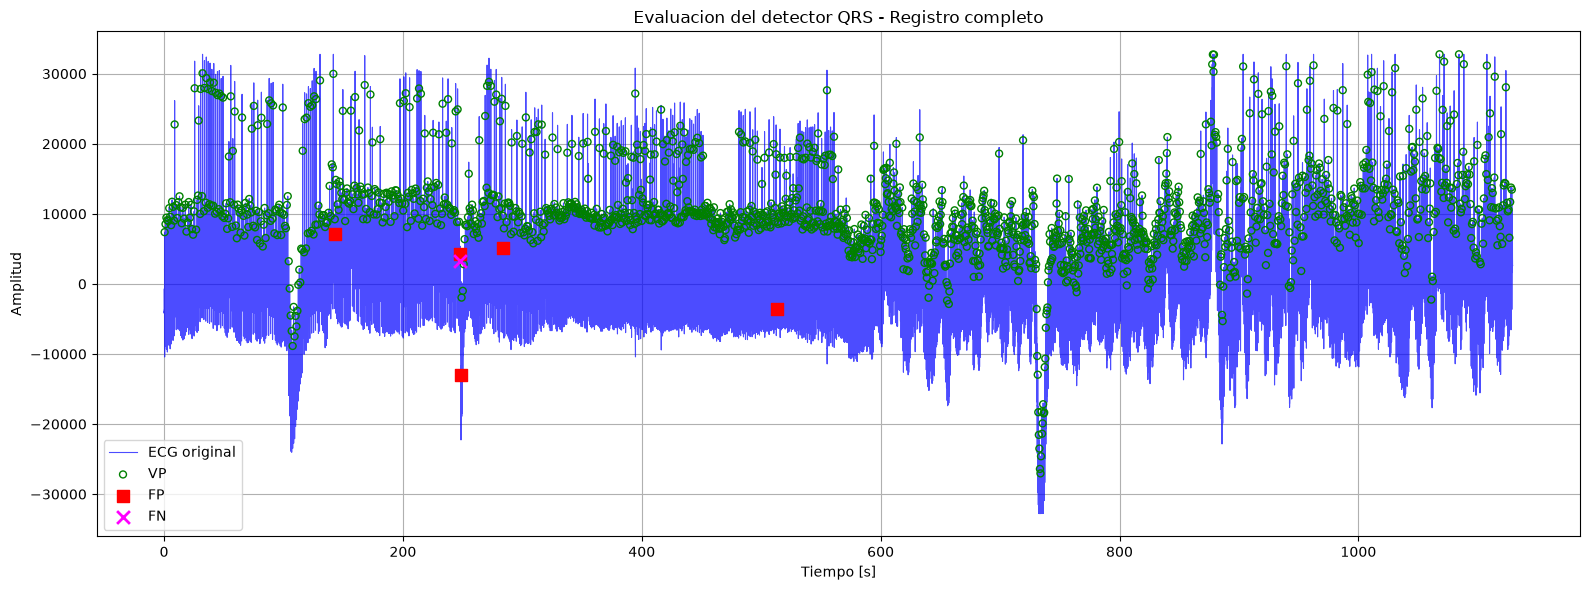

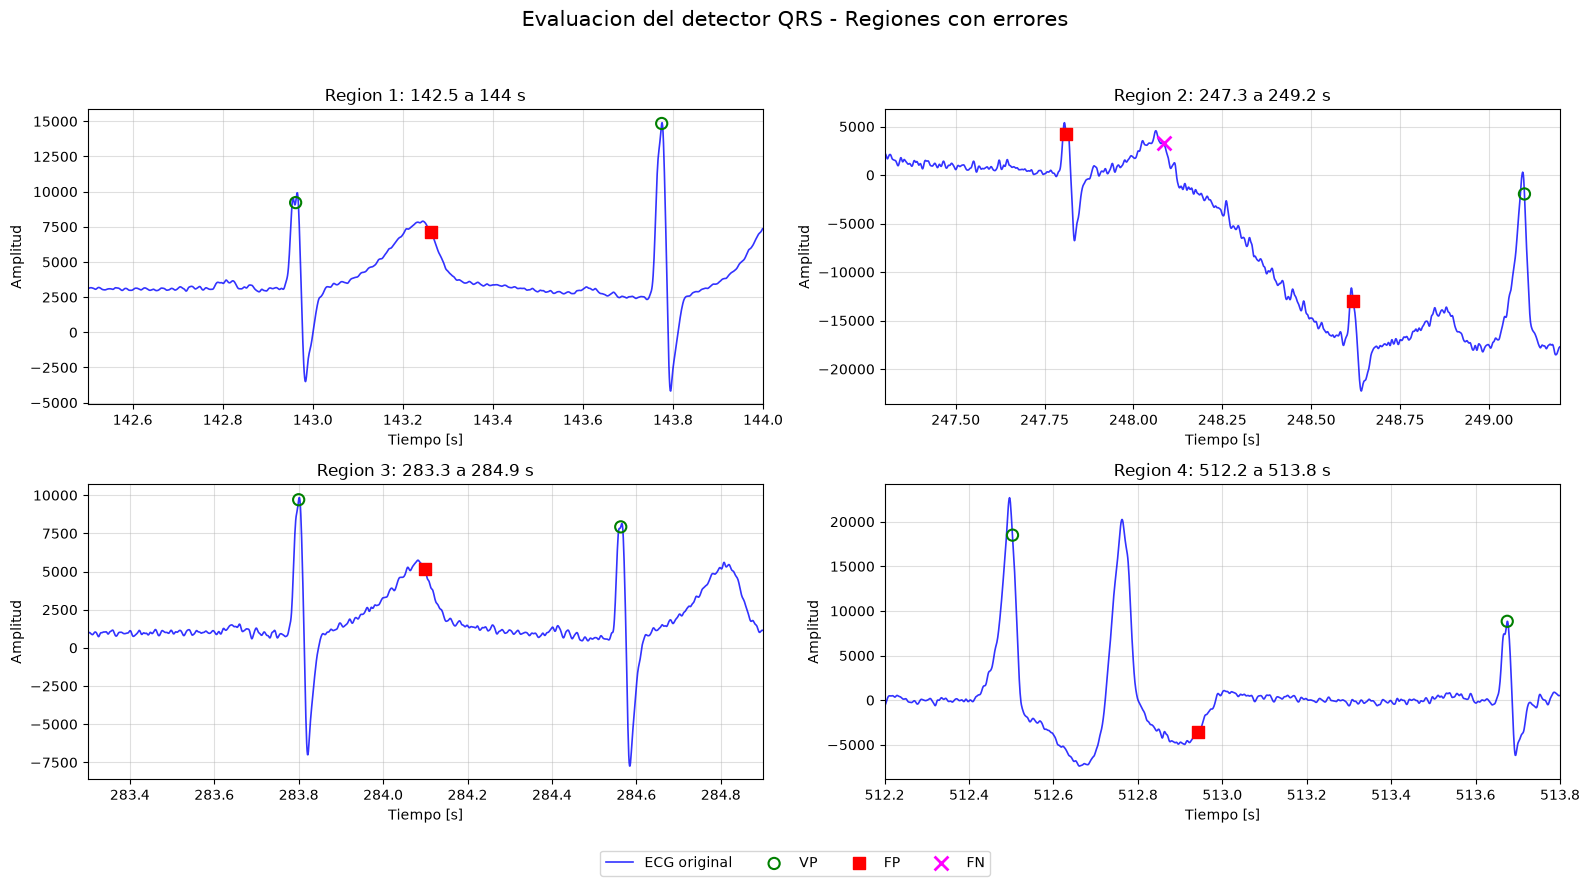

In [22]:

#%% GRAFICO COMPLETO - VP, FP Y FN

t = np.arange(len(s)) / fs

plt.figure(figsize=(16, 6))

# ECG original
plt.plot(t, s, color='blue', linewidth=0.8,
         alpha=0.7, label='ECG original')

# Verdaderos positivos
plt.scatter(vp_det / fs, s[vp_det],
            facecolors='none', edgecolors='green',
            marker='o', s=25, label='VP', zorder=5)

# Falsos positivos
plt.scatter(fp_det / fs, s[fp_det],
            color='red', marker='s',
            s=65, label='FP', zorder=6)

# Falsos negativos
plt.scatter(fn_ref / fs, s[fn_ref],
            color='magenta', marker='x',
            s=85, linewidths=2,
            label='FN', zorder=6)

plt.title('Evaluacion del detector QRS - Registro completo')
plt.xlabel('Tiempo [s]')
plt.ylabel('Amplitud')
plt.grid()
plt.legend()
plt.tight_layout()
plt.show()



#%% ZOOM - REGIONES CON ERRORES DE DETECCION

# Intervalos de interes en segundos
regiones_error = (
    [142.5, 144],
    [247.3, 249.2],
    [283.3, 284.9],
    [512.2, 513.8],
)

fig, ax = plt.subplots(2, 2, figsize=(16, 9))
ax = ax.flatten()

for k, (t_ini, t_fin) in enumerate(regiones_error):

    inicio = int(t_ini * fs)
    fin = int(t_fin * fs)

    zoom = np.arange(inicio, fin)

    # Detecciones dentro de cada region
    vp_zoom = vp_det[(vp_det >= inicio) & (vp_det < fin)]
    fp_zoom = fp_det[(fp_det >= inicio) & (fp_det < fin)]
    fn_zoom = fn_ref[(fn_ref >= inicio) & (fn_ref < fin)]

    # ECG original
    ax[k].plot(zoom / fs, s[zoom],
               color='blue', linewidth=1.2,
               alpha=0.8, label='ECG original')

    # Verdaderos positivos: circulos verdes
    ax[k].scatter(vp_zoom / fs, s[vp_zoom],
                  facecolors='none', edgecolors='green',
                  marker='o', s=65, linewidths=1.5,
                  label='VP', zorder=5)

    # Falsos positivos: cuadrados rojos
    ax[k].scatter(fp_zoom / fs, s[fp_zoom],
                  color='red', marker='s',
                  s=85, label='FP', zorder=6)

    # Falsos negativos: cruces violetas
    ax[k].scatter(fn_zoom / fs, s[fn_zoom],
                  color='magenta', marker='x',
                  s=100, linewidths=2,
                  label='FN', zorder=6)

    ax[k].set_title(
        f'Region {k+1}: {t_ini} a {t_fin} s',
        fontsize=12
    )

    ax[k].set_xlabel('Tiempo [s]')
    ax[k].set_ylabel('Amplitud')
    ax[k].set_xlim(t_ini, t_fin)
    ax[k].grid(True, alpha=0.4)

# Leyenda unica para toda la figura
handles, labels = ax[0].get_legend_handles_labels()

fig.legend(handles, labels,
           loc='lower center', ncol=4,
           bbox_to_anchor=(0.5, 0.01))

fig.suptitle('Evaluacion del detector QRS - Regiones con errores',
             fontsize=15)

plt.tight_layout(rect=[0, 0.06, 1, 0.95])
plt.show()




Al representar los verdaderos positivos (VP), falsos positivos (FP) y falsos negativos (FN) sobre el ECG, observamos que los errores se distribuyen en cuatro regiones del registro, aunque la mayor concentración se encuentra aproximadamente entre los 247 y 249 segundos, donde la señal presenta una perturbación de gran amplitud y un desplazamiento brusco y pronunciado de la línea de base.

En esta región crítica, el detector identifica dos máximos que no corresponden a las detecciones de referencia (FP) y omite un latido real (FN). Esto sugiere que las alteraciones morfológicas severas pueden afectar la correlación con el patrón QRS y generar errores de detección, incluso después del prefiltrado pasabajos.

Por otro lado, en las regiones cercanas a los 143 y 284 segundos, los falsos positivos parecen estar asociados a las ondas T, que también generan cierta similitud con el patrón utilizado. Asimismo, alrededor de los 513 segundos aparece otra falsa detección en una zona con una morfología particularmente pronunciada.

Sin embargo, fuera de estas regiones, las detecciones coinciden prácticamente en su totalidad con los latidos de referencia. Esto concuerda con los elevados valores de sensibilidad (99,95 %) y VPP (99,74 %) obtenidos, evidenciando que el método presenta un excelente desempeño general, aunque su eficacia puede verse limitada ante interferencias intensas o componentes de la señal que producen coincidencias con la plantilla.

## Bonus
#### ¿Podría funcionar el detector basado en el filtro adaptado con un latido perteneciente a otro registro o paciente?

Sí, podría funcionar, siempre que el patrón utilizado presente una morfología suficientemente similar a los complejos QRS del nuevo registro. Sin embargo, una de las principales limitaciones del filtro adaptado es su dependencia de la plantilla de referencia.

Las diferencias morfológicas, de duración o polaridad entre pacientes pueden reducir la correlación y generar errores de detección. Por lo tanto, aunque el método podría funcionar con un patrón de otro paciente, no se garantiza el mismo desempeño y sería necesario evaluar nuevamente sus métricas de detección.

#### Propuesta de mejora de los estimadores de la línea de base mediante técnicas multirate
en fin: La idea es que, en la versión multirate, primero reducimos la frecuencia de muestreo por un factor de 10 mediante un diezmado con filtrado antialiasing, después aplicamos las medianas y finalmente interpolamos nuevamente.

Como posible mejora del estimador de línea de base, se propone utilizar técnicas multirate para reducir el costo computacional del filtrado por mediana. Dado que el movimiento de línea de base presenta variaciones de muy baja frecuencia, podemos reducir la frecuencia de muestreo del ECG de 1000 Hz a 100 Hz, aplicando previamente un filtrado antialiasing.

Sobre la señal diezmada se aplican las dos medianas de 200 y 600 ms, utilizando ventanas de 21 y 61 muestras, respectivamente. Finalmente, se interpola la estimación para recuperar la frecuencia de muestreo original y poder restarla del ECG.

A continuación, se comparan ambas implementaciones, analizando las estimaciones obtenidas y sus respectivos tiempos de procesamiento, con el objetivo de evaluar si la reducción del costo computacional justifica las posibles diferencias introducidas en el filtrado.

RESULTADOS MULTIRATE
Frecuencia original: 1000 Hz
Frecuencia reducida: 100.0 Hz
Tiempo mediana original: 0.0055 s
Tiempo mediana multirate: 0.0042 s
Factor de aceleracion: 1.32 veces
RMSE entre estimaciones: 68.54


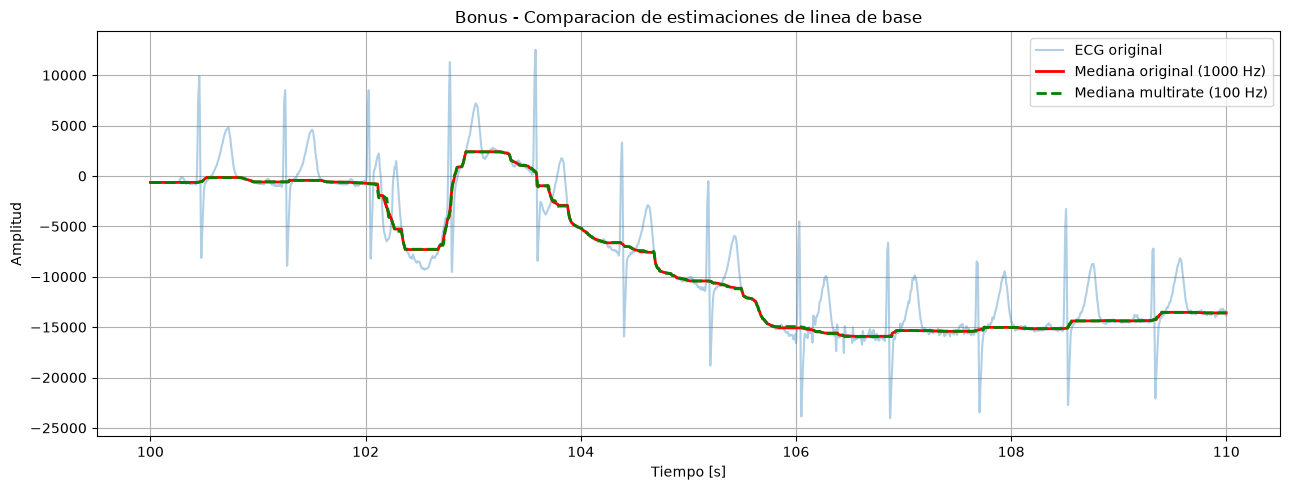

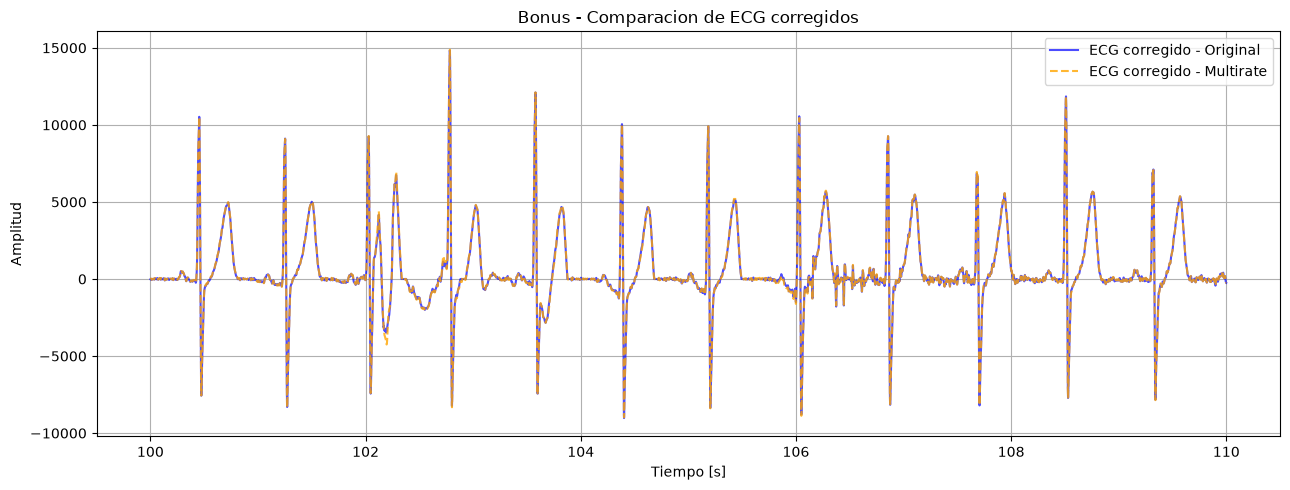

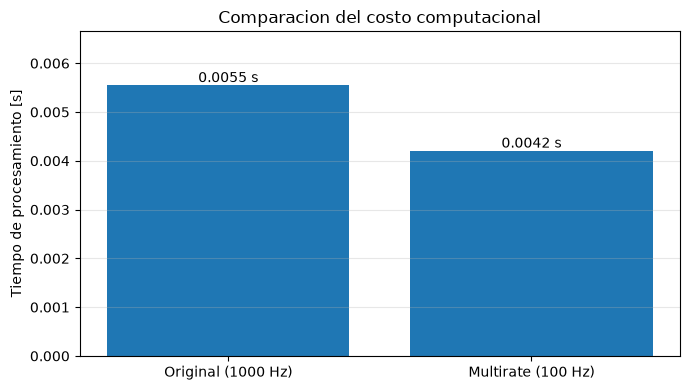

In [11]:

#%% BONUS A - FILTRADO MULTIRATE

import time

# 1. PARAMETROS

D = 10                  # Factor de diezmado
fs_nueva = fs / D       # 100 Hz

# Region de interes: 100 a 110 segundos
inicio = int(100 * fs)
fin = int(110 * fs)

# Agregamos un margen para evitar efectos de borde
margen = int(2 * fs)

inicio_ext = max(0, inicio - margen)
fin_ext = min(len(s), fin + margen)

s_region = s[inicio_ext:fin_ext]

# Indices de la region original dentro del segmento ampliado
i0 = inicio - inicio_ext
i1 = fin - inicio_ext

# Ventanas del filtro original
N1 = 201
N2 = 601

# Ventanas equivalentes a 100 Hz
N1_red = 21
N2_red = 61

# 2. FILTRO DE MEDIANA ORIGINAL (1000 Hz)


t0 = time.perf_counter()

med_200 = signal.medfilt(s_region, kernel_size=N1)
b_original = signal.medfilt(med_200, kernel_size=N2)

tiempo_original = time.perf_counter() - t0


# 3. FILTRO DE MEDIANA MULTIRATE (100 Hz)


t0 = time.perf_counter()

# Diezmado por 10 con filtro antialiasing incorporado
s_reducida = signal.resample_poly(s_region, up=1, down=D)

# Aplicamos las dos medianas a 100 Hz
med_200_red = signal.medfilt(s_reducida, kernel_size=N1_red)
b_reducida = signal.medfilt(med_200_red, kernel_size=N2_red)

# Interpolamos nuevamente a 1000 Hz
b_multirate = signal.resample_poly(b_reducida, up=D, down=1)

# Ajustamos la longitud al registro original
b_multirate = b_multirate[:len(s_region)]

tiempo_multirate = time.perf_counter() - t0


# 4. RECORTAMOS Y OBTENEMOS LOS ECG CORREGIDOS


ecg_original = s_region[i0:i1]

b_original = b_original[i0:i1]
b_multirate = b_multirate[i0:i1]

ecg_corregido_original = ecg_original - b_original
ecg_corregido_multirate = ecg_original - b_multirate

t_region = np.arange(inicio, fin) / fs


# 5. COMPARACION NUMERICA


# Diferencia entre las dos estimaciones de linea de base
rmse = np.sqrt(np.mean((b_original - b_multirate)**2))

print("RESULTADOS MULTIRATE")
print("Frecuencia original:", fs, "Hz")
print("Frecuencia reducida:", fs_nueva, "Hz")

print(f"Tiempo mediana original: {tiempo_original:.4f} s")
print(f"Tiempo mediana multirate: {tiempo_multirate:.4f} s")

if tiempo_multirate > 0:
    print(f"Factor de aceleracion: "
          f"{tiempo_original / tiempo_multirate:.2f} veces")

print(f"RMSE entre estimaciones: {rmse:.2f}")


# 6. GRAFICO 1 - LINEA DE BASE


plt.figure(figsize=(13, 5))

plt.plot(t_region, ecg_original,
         label='ECG original', alpha=0.35)

plt.plot(t_region, b_original,
         label='Mediana original (1000 Hz)',
         color='red', linewidth=2)

plt.plot(t_region, b_multirate,
         label='Mediana multirate (100 Hz)',
         color='green', linestyle='--', linewidth=2)

plt.title('Bonus - Comparacion de estimaciones de linea de base')
plt.xlabel('Tiempo [s]')
plt.ylabel('Amplitud')
plt.grid()
plt.legend()
plt.tight_layout()
plt.show()


# 7. GRAFICO 2 - ECG CORREGIDO


plt.figure(figsize=(13, 5))

plt.plot(t_region, ecg_corregido_original,
         label='ECG corregido - Original',
         color='blue', alpha=0.7)

plt.plot(t_region, ecg_corregido_multirate,
         label='ECG corregido - Multirate',
         color='orange', linestyle='--', alpha=0.8)

plt.title('Bonus - Comparacion de ECG corregidos')
plt.xlabel('Tiempo [s]')
plt.ylabel('Amplitud')
plt.grid()
plt.legend()
plt.tight_layout()
plt.show()


# 8. GRAFICO 3 - TIEMPOS DE PROCESAMIENTO

plt.figure(figsize=(7, 4))

metodos = ['Original (1000 Hz)', 'Multirate (100 Hz)']
tiempos = [tiempo_original, tiempo_multirate]

barras = plt.bar(metodos, tiempos)

for barra, valor in zip(barras, tiempos):
    plt.text(barra.get_x() + barra.get_width()/2,
             valor, f'{valor:.4f} s',
             ha='center', va='bottom')

plt.title('Comparacion del costo computacional')
plt.ylabel('Tiempo de procesamiento [s]')
plt.ylim(0, max(tiempos) * 1.2)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


A partir de los gráficos obtenidos, observamos que ambas técnicas producen estimaciones de la línea de base prácticamente coincidentes. Asimismo, las señales corregidas presentan una superposición casi completa, indicando que el procesamiento multirate permite conservar resultados muy similares a los del método original.

En cuanto al costo computacional, observamos que los tiempos de ejecución variaron entre distintas pruebas. Si bien en algunas ejecuciones el método multirate resultó más rápido, en otras presentó tiempos superiores a los del método original. Esto se debe a que, aunque el diezmado reduce la cantidad de muestras procesadas, también se incorporan operaciones adicionales de filtrado antialiasing e interpolación. Además, los tiempos medidos son muy pequeños y pueden verse afectados por la carga del procesador y las condiciones de ejecución.

Por lo tanto, el procesamiento multirate permitió obtener resultados de filtrado similares utilizando una menor frecuencia de muestreo, pero no garantizó una reducción del tiempo de ejecución para el intervalo analizado.

## Conclusión
A lo largo de este trabajo práctico, encaramos dos de los problemas más clásicos al procesar señales de ECG: eliminar la deriva de la línea de base y detectar automáticamente los complejos QRS. Al poner a prueba distintos algoritmos, comprobamos que cada enfoque tiene sus ventajas y sus puntos débiles.

Por un lado, los **filtros no lineales (como el de mediana)** nos resultaron muy prácticos para estimar la línea de base sin necesidad de usar puntos de anclaje. El problema es que su funcionamiento depende muchísimo del tamaño de las ventanas; si no ajustamos bien ese parámetro, el costo computacional se dispara o terminamos deformando la señal original.

En cambio, la interpolación con **Splines Cúbicos** demostró ser una técnica súper eficiente que traza líneas de base suaves sin alterar la forma de los latidos. Pero, como vimos en los gráficos, tiene una limitación enorme: depende 100% de que ubiquemos bien los nodos isoeléctricos. Si usamos reglas fijas (como retroceder 80 ms desde el pico), el método fracasa frente a derivas severas o latidos ectópicos, porque los nodos caen en la pendiente y terminan deformando toda la señal.

Finalmente, para detectar la ubicación temporal de los latidos, el **Filtro Adaptado** nos resolvió el problema morfológico convirtiéndolo en una simple búsqueda de picos de energía. Obviamente tiene la contra de que requiere conocer la plantilla de referencia de antemano y que los ruidos muy bruscos lo engañan, pero los números hablaron por sí solos: fue el método más robusto y eficiente, logrando una Sensibilidad del 99,95 % y un VPP del 99,89 %.
A modo de cierre, el desarrollo de este trabajo nos permitió comprobar empíricamente que ningún método de procesamiento es perfecto por sí solo. Al trabajar con un registro real tan extenso, quedó claro que no alcanza con aplicar un algoritmo aislado: la clave está en acondicionar correctamente la señal, ajustar con criterio los parámetros de diseño (como el tamaño de las ventanas, el anclaje de los nodos o los umbrales de prominencia) y tener siempre presentes las limitaciones matemáticas de cada técnica para saber interpretar cuándo y por qué el detector puede fallar.